
# EARTHQUAKE DAMAGE PREDICTION

## 1. Introduction

Earthquakes are natural disasters that can cause severe
damage to buildings and infrastructure.

The extent of building damage depends on various factors,
including geographical location, foundation type,
construction materials, building age and structural design.

This project focuses on predicting building damage grades
using Machine Learning techniques.

## 2. Problem Statement

To develop a Machine Learning classification model that
predicts the level of damage sustained by buildings during
the 2015 Gorkha earthquake in Nepal.




In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load training datasets

train_values = pd.read_csv("train_values.csv")
train_labels = pd.read_csv("train_labels.csv")

print("Training features:", train_values.shape)
print("Training labels:", train_labels.shape)

# Merge datasets
df = pd.merge(
    train_values,
    train_labels,
    on='building_id',
    how='inner',
    validate='one_to_one'
)

print("Final dataset shape:", df.shape)

display(df.head())


Training features: (260601, 39)
Training labels: (260601, 2)
Final dataset shape: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


In [3]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   building_id                             260601 non-null  int64 
 1   geo_level_1_id                          260601 non-null  int64 
 2   geo_level_2_id                          260601 non-null  int64 
 3   geo_level_3_id                          260601 non-null  int64 
 4   count_floors_pre_eq                     260601 non-null  int64 
 5   age                                     260601 non-null  int64 
 6   area_percentage                         260601 non-null  int64 
 7   height_percentage                       260601 non-null  int64 
 8   land_surface_condition                  260601 non-null  object
 9   foundation_type                         260601 non-null  object
 10  roof_type                               260601 non-null 

In [4]:
# Generate statistical summary
df.describe()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
count,2.606010e+05,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000
mean,5.256755e+05,13.900353,701.074685,6257.876148,2.129723,26.535029,8.018051,5.434365,0.088645,0.761935,0.034332,0.018235,0.068154,0.075268,0.254988,0.085011,0.042590,0.015859,0.014985,0.983949,0.111880,0.064378,0.033626,0.008101,0.000940,0.000361,0.001071,0.000188,0.000146,0.000088,0.005119,2.238272
std,3.045450e+05,8.033617,412.710734,3646.369645,0.727665,73.565937,4.392231,1.918418,0.284231,0.425900,0.182081,0.133800,0.252010,0.263824,0.435855,0.278899,0.201931,0.124932,0.121491,0.418389,0.315219,0.245426,0.180265,0.089638,0.030647,0.018989,0.032703,0.013711,0.012075,0.009394,0.071364,0.611814
min,4.000000e+00,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.611900e+05,7.000000,350.000000,3073.000000,2.000000,10.000000,5.000000,4.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,5.257570e+05,12.000000,702.000000,6270.000000,2.000000,15.000000,7.000000,5.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,7.897620e+05,21.000000,1050.000000,9412.000000,2.000000,30.000000,9.000000,6.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,1.052934e+06,30.000000,1427.000000,12567.000000,9.000000,995.000000,100.000000,32.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,9.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


In [5]:
# Statistical summary of categorical columns
df.describe(include='object')

,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,legal_ownership_status
count,260601,260601,260601,260601,260601,260601,260601,260601
unique,3,5,3,5,4,4,10,4
top,t,r,n,f,q,s,d,v
freq,216757,219196,182842,209619,165282,202090,250072,250939


In [6]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
building_id                               0
geo_level_1_id                            0
geo_level_2_id                            0
geo_level_3_id                            0
count_floors_pre_eq                       0
age                                       0
area_percentage                           0
height_percentage                         0
land_surface_condition                    0
foundation_type                           0
roof_type                                 0
ground_floor_type                         0
other_floor_type                          0
position                                  0
plan_configuration                        0
has_superstructure_adobe_mud              0
has_superstructure_mud_mortar_stone       0
has_superstructure_stone_flag             0
has_superstructure_cement_mortar_stone    0
has_superstructure_mud_mortar_brick       0
has_superstructure_cement_mortar_brick    0
has_superstructure_timber                 0
h

In [7]:
# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

display(missing_report)

,Missing Count,Missing Percentage
building_id,0,0.0
geo_level_1_id,0,0.0
geo_level_2_id,0,0.0
geo_level_3_id,0,0.0
count_floors_pre_eq,0,0.0
age,0,0.0
area_percentage,0,0.0
height_percentage,0,0.0
land_surface_condition,0,0.0
foundation_type,0,0.0



### Missing Value Analysis – Observation

The dataset was examined for missing values across all
40 columns, including numerical, categorical, binary
and target variables.

The analysis identified zero missing values across
260,601 building records.

Therefore, missing-value imputation techniques were
not required for this dataset.

However, further data quality checks will be performed
to identify duplicate records, invalid values and outliers.


In [10]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Check duplicate building IDs
duplicate_ids = df['building_id'].duplicated().sum()

print("Duplicate Building IDs:", duplicate_ids)

Total Duplicate Records: 0
Duplicate Building IDs: 0



### Duplicate Analysis – Observation

The dataset was checked for duplicate records and
duplicate building identifiers.

The analysis found zero duplicate rows and zero
duplicate building IDs among 260,601 observations.

Therefore, no duplicate removal was required.


### Outlier Analysis

In [12]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nTotal Numerical Columns:", len(numerical_columns))

Numerical Columns:
['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other', 'damage_grade']

Total Numerical Columns: 32


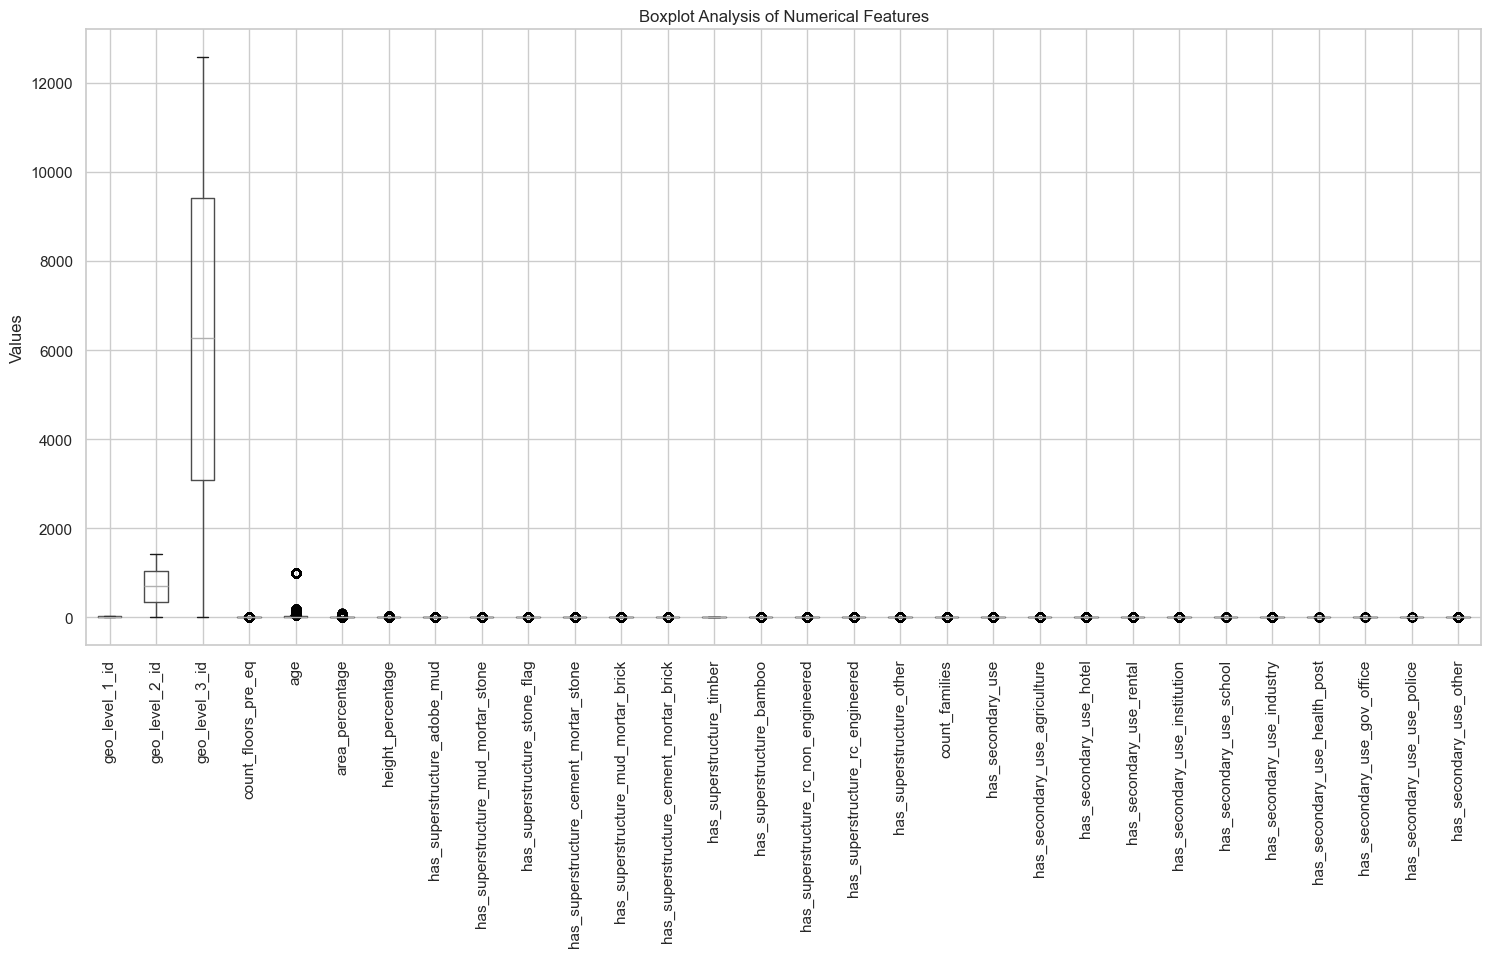

In [13]:
# Visualize numerical feature distributions
df[numerical_columns].drop(
    columns=['building_id', 'damage_grade'],
    errors='ignore'
).boxplot(figsize=(18, 8), rot=90)

plt.title("Boxplot Analysis of Numerical Features")
plt.ylabel("Values")
plt.show()

### Outlier detection using the IQR method

In [14]:
# Select meaningful numerical building features
numerical_features = [
    'count_floors_pre_eq',
    'age',
    'area_percentage',
    'height_percentage',
    'count_families'
]

# Create an empty list to store results
outlier_results = []

# Calculate outliers using IQR
for col in numerical_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_results.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (
            len(outliers) / len(df)
        ) * 100
    })

# Display outlier report
outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))

,Feature,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,count_floors_pre_eq,2.0,2.0,0.0,2.0,2.0,103978,39.90
1,age,10.0,30.0,20.0,-20.0,60.0,12499,4.80
2,area_percentage,5.0,9.0,4.0,-1.0,15.0,13557,5.20
3,height_percentage,4.0,6.0,2.0,1.0,9.0,7843,3.01
4,count_families,1.0,1.0,0.0,1.0,1.0,34486,13.23



### Outlier Analysis – Observation

The Interquartile Range (IQR) method was used to identify
potential outliers in numerical building features.

The analysis identified different outlier percentages
across the selected variables.

The count_floors_pre_eq and count_families features
produced an IQR value of zero because their first and
third quartiles were equal.

This resulted in many observations being flagged by
the standard IQR method.

These observations cannot automatically be considered
incorrect because they may represent valid building
characteristics.

Therefore, no observations were removed during this
stage. The original dataset was retained to avoid
unnecessary information loss.


### Exploratory Data Analysis (EDA)

Damage Grade Distribution:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


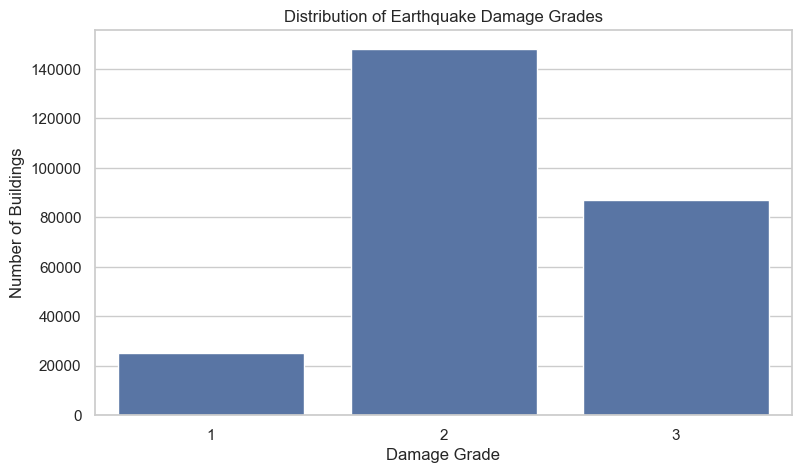

In [16]:
# Count buildings in each damage grade
damage_counts = df['damage_grade'].value_counts().sort_index()

print("Damage Grade Distribution:")
print(damage_counts)

# Visualize distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='damage_grade'
)

plt.title('Distribution of Earthquake Damage Grades')
plt.xlabel('Damage Grade')
plt.ylabel('Number of Buildings')

plt.show()

Damage Grade Percentage:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


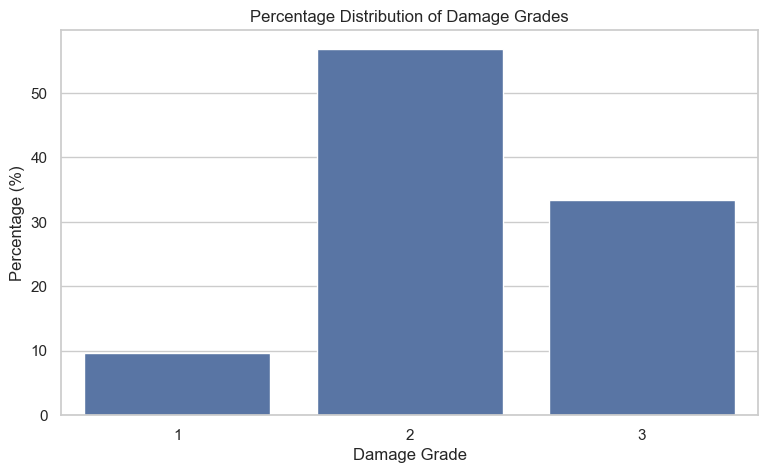

In [17]:
# Calculate percentage distribution
damage_percentage = (
    df['damage_grade']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Damage Grade Percentage:")
print(damage_percentage.round(2))

# Visualize percentage distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    x=damage_percentage.index,
    y=damage_percentage.values
)

plt.title('Percentage Distribution of Damage Grades')
plt.xlabel('Damage Grade')
plt.ylabel('Percentage (%)')

plt.show()


### Damage Grade Distribution – Observation

The target variable damage_grade contains three
categories: Grade 1, Grade 2 and Grade 3.

The analysis shows that Grade 1 accounts for 9.64%
of observations, Grade 2 accounts for 56.89%, and
Grade 3 accounts for 33.47%.

Grade 2 is the most frequently occurring category,
while Grade 1 is the least represented category.

This indicates class imbalance in the target variable.

Therefore, model evaluation will include macro
F1-score, precision, recall and confusion matrix
along with accuracy.



### Building age distribution by damage grade


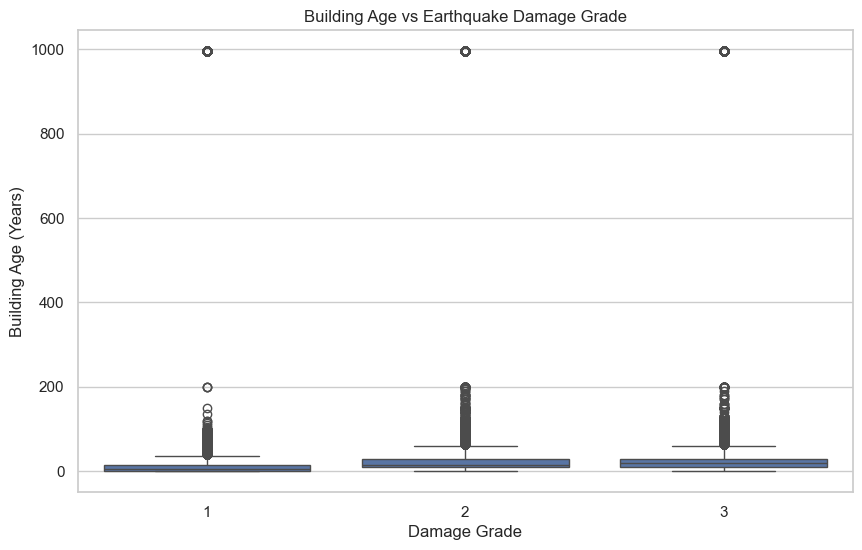

In [19]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='damage_grade',
    y='age'
)

plt.title('Building Age vs Earthquake Damage Grade')
plt.xlabel('Damage Grade')
plt.ylabel('Building Age (Years)')

plt.show()

### average and median building age

In [20]:
age_analysis = df.groupby('damage_grade')['age'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print("Building Age Analysis by Damage Grade:")

display(age_analysis.round(2))

Building Age Analysis by Damage Grade:


,count,mean,median,min,max
damage_grade,,,,,
1,25124,17.32,5.0,0,995
2,148259,27.34,15.0,0,995
3,87218,27.82,20.0,0,995



### Building Age vs Damage Grade – Observation

The boxplot analysis was performed to examine the
relationship between building age and earthquake
damage grade.

The median building age appears relatively lower
for Grade 1 compared with Grades 2 and 3.

The distributions overlap, indicating that building
age alone cannot explain the level of earthquake damage.

Several extreme age observations were also identified.
These require further investigation before any treatment.

Therefore, building age should be considered along
with other structural and geographical features.


In [23]:
# Examine building age statistics
print("Building Age Statistics:")
display(df['age'].describe())

# Identify buildings with age above 100 years
extreme_age = df[df['age'] > 100]

print("\nBuildings with age above 100 years:")
print("Total records:", len(extreme_age))

# Display extreme age frequency
print("\nHighest age values:")
print(extreme_age['age'].value_counts().sort_index().tail(15))

Building Age Statistics:


count    260601.000000
mean         26.535029
std          73.565937
min           0.000000
25%          10.000000
50%          15.000000
75%          30.000000
max         995.000000
Name: age, dtype: float64


Buildings with age above 100 years:
Total records: 2124

Highest age values:
age
135       5
140       9
145       3
150     142
155       1
160       6
165       2
170       6
175       5
180       7
185       1
190       3
195       2
200     106
995    1390
Name: count, dtype: int64


In [22]:
age_analysis = df.groupby('damage_grade')['age'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

display(age_analysis.round(2))

,count,mean,median,min,max
damage_grade,,,,,
1,25124,17.32,5.0,0,995
2,148259,27.34,15.0,0,995
3,87218,27.82,20.0,0,995


In [24]:
# Investigate buildings with age 995
age_995 = df[df['age'] == 995]

print("Buildings with age 995:", len(age_995))

print("\nDamage grade distribution for age 995:")
print(age_995['damage_grade'].value_counts().sort_index())

print("\nAge 995 percentage:")
print(round((len(age_995) / len(df)) * 100, 2), "%")

Buildings with age 995: 1390

Damage grade distribution for age 995:
damage_grade
1    179
2    822
3    389
Name: count, dtype: int64

Age 995 percentage:
0.53 %



### Building Age Analysis – Observation

The average building age was found to be 26.54 years,
while the median age was 15 years.

The average age for Grade 1, Grade 2 and Grade 3
buildings was 17.32, 27.34 and 27.82 years respectively.

The median ages were 5, 15 and 20 years respectively.

The results suggest an association between building
age and earthquake damage severity.

An unusual maximum age value of 995 years was identified.
A total of 1,390 records contain this value.

These observations require further investigation before
deciding on any data transformation or treatment.


### Foundation type distribution

Foundation Type Distribution:
foundation_type
r    219196
w     15118
u     14260
i     10579
h      1448
Name: count, dtype: int64


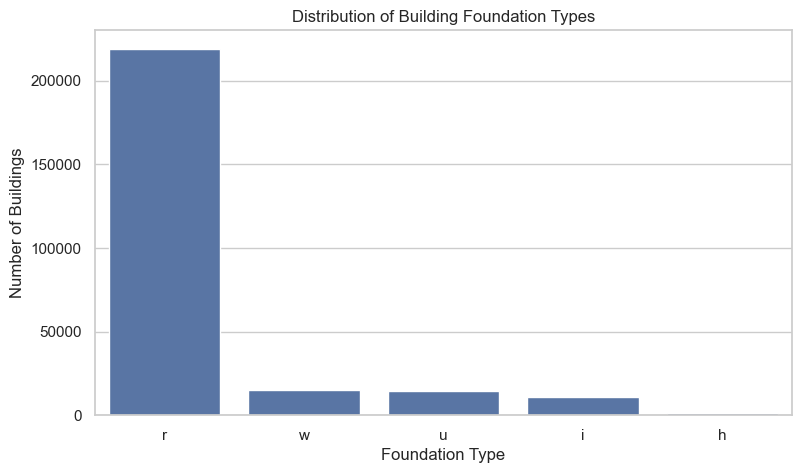

In [25]:
# Count buildings by foundation type

print("Foundation Type Distribution:")

print(df['foundation_type'].value_counts())

# Visualize foundation types

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='foundation_type',
    order=df['foundation_type'].value_counts().index
)

plt.title('Distribution of Building Foundation Types')
plt.xlabel('Foundation Type')
plt.ylabel('Number of Buildings')

plt.show()

### Foundation type vs damage grade

Foundation Type vs Damage Grade:


damage_grade,1,2,3
foundation_type,,,
h,358,579,511
i,6004,4354,221
r,10720,125515,82961
u,3689,8541,2030
w,4353,9270,1495


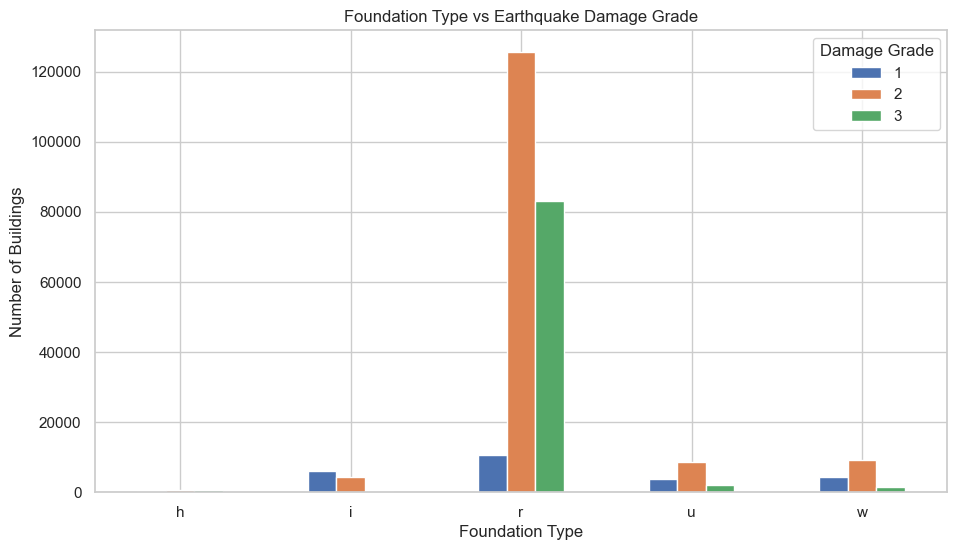

In [26]:
# Analyze foundation type against damage grade

foundation_damage = pd.crosstab(
    df['foundation_type'],
    df['damage_grade']
)

print("Foundation Type vs Damage Grade:")

display(foundation_damage)

# Visualize relationship

foundation_damage.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Foundation Type vs Earthquake Damage Grade')
plt.xlabel('Foundation Type')
plt.ylabel('Number of Buildings')
plt.xticks(rotation=0)
plt.legend(title='Damage Grade')

plt.show()

In [27]:
# Calculate damage grade percentages
foundation_percentage = pd.crosstab(
    df['foundation_type'],
    df['damage_grade'],
    normalize='index'
) * 100

print("Foundation Type Damage Percentage:")
display(foundation_percentage.round(2))

Foundation Type Damage Percentage:


damage_grade,1,2,3
foundation_type,,,
h,24.72,39.99,35.29
i,56.75,41.16,2.09
r,4.89,57.26,37.85
u,25.87,59.89,14.24
w,28.79,61.32,9.89


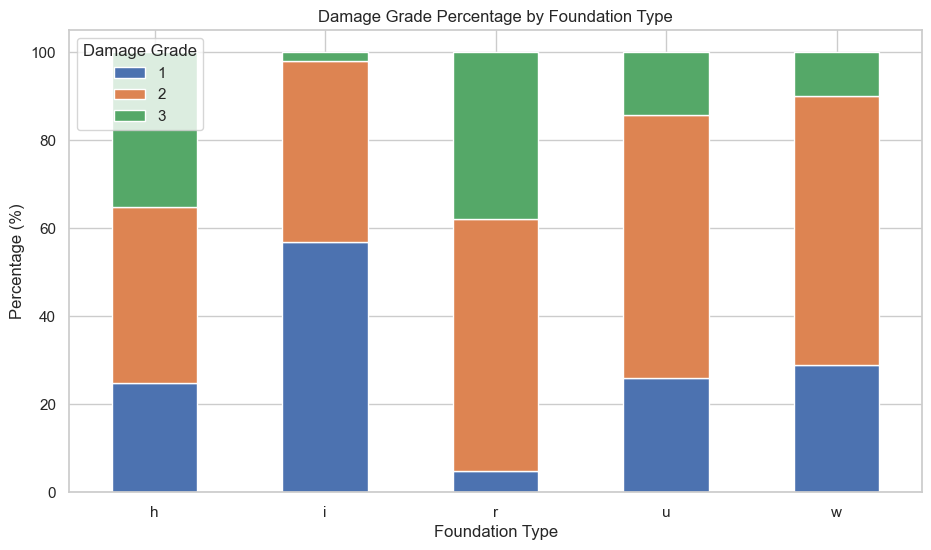

In [28]:
# Plot percentage distribution
foundation_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Damage Grade Percentage by Foundation Type')
plt.xlabel('Foundation Type')
plt.ylabel('Percentage (%)')

plt.legend(title='Damage Grade')
plt.xticks(rotation=0)

plt.show()


### Foundation Type Analysis – Preliminary Observation

The foundation type distribution indicates that category
'r' is the most frequently occurring foundation type.

The count-based comparison shows that Grade 2 represents
the largest number of buildings within the most common
foundation category.

However, raw counts are influenced by the frequency of
each foundation type.

Therefore, percentage-based analysis is required to
compare damage distributions fairly across categories.



### Foundation Type vs Damage Grade – Observation

The analysis was performed to examine the relationship
between foundation types and earthquake damage grades.

Foundation type 'r' represents the largest category
in the dataset. Grade 2 and Grade 3 account for most
observations within this category.

Foundation type 'i' shows a comparatively high proportion
of Grade 1 buildings.

Foundation types 'u' and 'w' are also dominated by
Grade 2 observations.

Foundation type 'h' has a very small representation,
so its percentage distribution should be interpreted
with caution.

The results suggest that foundation type may be an
important predictive feature.

However, these relationships do not establish causation.


Roof Type Distribution:
roof_type
n    182842
q     61576
x     16183
Name: count, dtype: int64


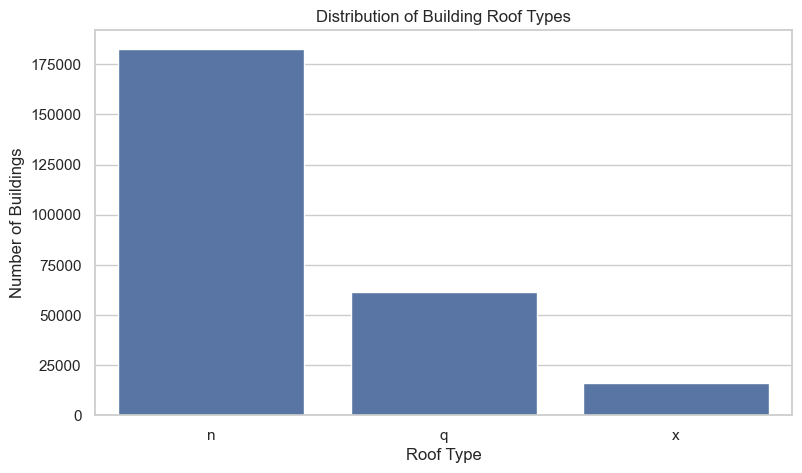

In [29]:
# Count buildings by roof type

print("Roof Type Distribution:")

print(df['roof_type'].value_counts())

# Visualize roof type distribution

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='roof_type',
    order=df['roof_type'].value_counts().index
)

plt.title('Distribution of Building Roof Types')
plt.xlabel('Roof Type')
plt.ylabel('Number of Buildings')

plt.show()

Roof Type vs Damage Grade:


damage_grade,1,2,3
roof_type,,,
n,13547,106447,62848
q,3926,34009,23641
x,7651,7803,729


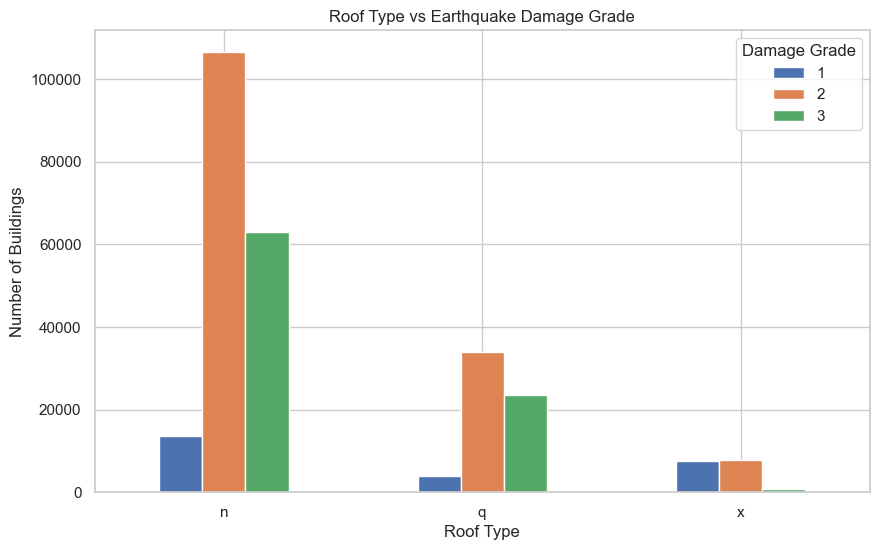

In [30]:
# Create a frequency table

roof_damage = pd.crosstab(
    df['roof_type'],
    df['damage_grade']
)

print("Roof Type vs Damage Grade:")

display(roof_damage)

# Visualize the relationship

roof_damage.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Roof Type vs Earthquake Damage Grade')
plt.xlabel('Roof Type')
plt.ylabel('Number of Buildings')
plt.xticks(rotation=0)
plt.legend(title='Damage Grade')

plt.show()

Roof Type Damage Percentage:


damage_grade,1,2,3
roof_type,,,
n,7.41,58.22,34.37
q,6.38,55.23,38.39
x,47.28,48.22,4.50


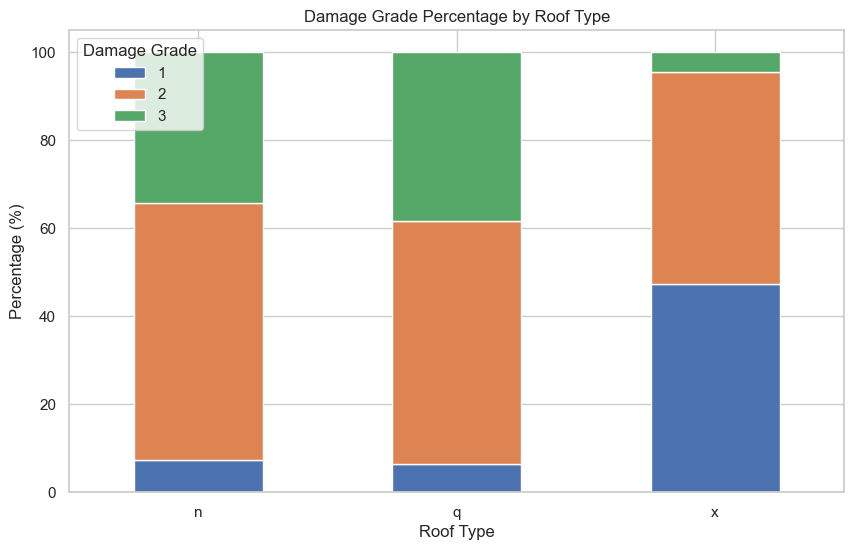

In [31]:
# Calculate percentage distribution

roof_percentage = pd.crosstab(
    df['roof_type'],
    df['damage_grade'],
    normalize='index'
) * 100

print("Roof Type Damage Percentage:")

display(roof_percentage.round(2))

# Visualize percentage distribution

roof_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Damage Grade Percentage by Roof Type')
plt.xlabel('Roof Type')
plt.ylabel('Percentage (%)')
plt.legend(title='Damage Grade')
plt.xticks(rotation=0)

plt.show()


### Roof Type vs Damage Grade – Observation

The analysis identified three roof categories: n, q and x.

Roof type n is the most frequently occurring category,
followed by q and x.

The percentage analysis indicates that Grade 2 is the
dominant damage category for roof types n and q.

Roof type x shows a different distribution, with
Grade 1 and Grade 2 accounting for most observations.

The results suggest that roof type may contribute
useful information for earthquake damage prediction.

However, the findings represent statistical associations
and do not establish a causal relationship.


### Ground floor type distribution

Ground Floor Type Distribution:
ground_floor_type
f    209619
x     24877
v     24593
z      1004
m       508
Name: count, dtype: int64


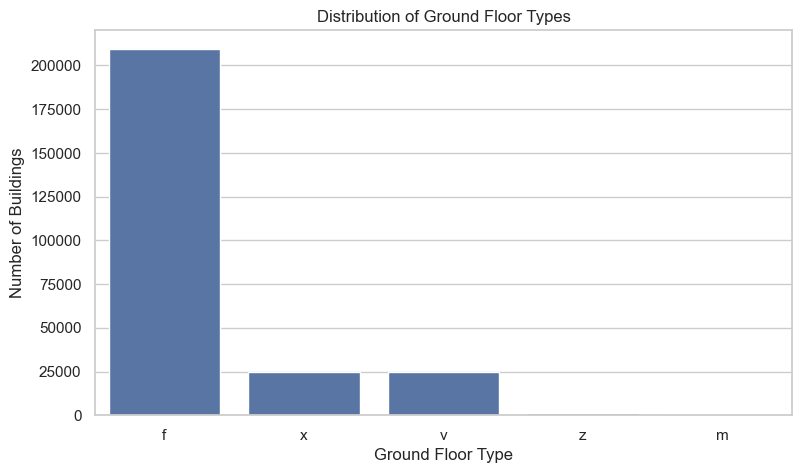

In [32]:
# Count buildings by ground floor type

print("Ground Floor Type Distribution:")

print(df['ground_floor_type'].value_counts())

# Visualize distribution

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='ground_floor_type',
    order=df['ground_floor_type'].value_counts().index
)

plt.title('Distribution of Ground Floor Types')
plt.xlabel('Ground Floor Type')
plt.ylabel('Number of Buildings')

plt.show()

### Ground floor type vs damage grade

Ground Floor Type vs Damage Grade:


damage_grade,1,2,3
ground_floor_type,,,
f,12474,119877,77268
m,90,343,75
v,10309,12971,1313
x,2052,14536,8289
z,199,532,273


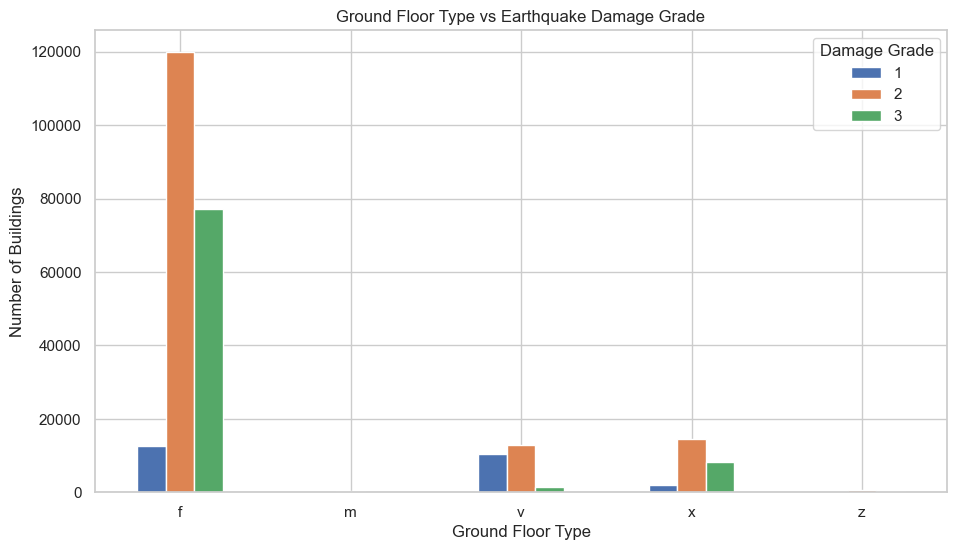

In [33]:
# Create frequency table

ground_floor_damage = pd.crosstab(
    df['ground_floor_type'],
    df['damage_grade']
)

print("Ground Floor Type vs Damage Grade:")

display(ground_floor_damage)

# Visualize relationship

ground_floor_damage.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Ground Floor Type vs Earthquake Damage Grade')
plt.xlabel('Ground Floor Type')
plt.ylabel('Number of Buildings')

plt.xticks(rotation=0)
plt.legend(title='Damage Grade')

plt.show()

### Ground floor percentage analysis

Ground Floor Damage Percentage:


damage_grade,1,2,3
ground_floor_type,,,
f,5.95,57.19,36.86
m,17.72,67.52,14.76
v,41.92,52.74,5.34
x,8.25,58.43,33.32
z,19.82,52.99,27.19


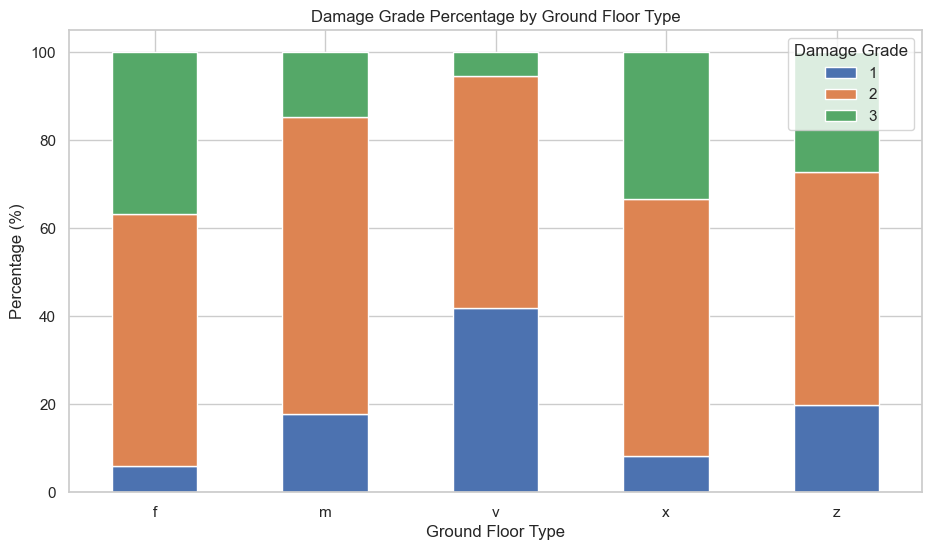

In [34]:
# Calculate damage grade percentages

ground_floor_percentage = pd.crosstab(
    df['ground_floor_type'],
    df['damage_grade'],
    normalize='index'
) * 100

print("Ground Floor Damage Percentage:")

display(ground_floor_percentage.round(2))

# Visualize percentage distribution

ground_floor_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Damage Grade Percentage by Ground Floor Type')
plt.xlabel('Ground Floor Type')
plt.ylabel('Percentage (%)')

plt.legend(title='Damage Grade')
plt.xticks(rotation=0)

plt.show()


### Ground Floor Type vs Damage Grade – Observation

The analysis identified five ground-floor categories:
f, m, v, x and z.

Category f represents the largest number of buildings
in the dataset, followed by categories x and v.

The percentage analysis shows differences in damage
grade distributions across ground-floor categories.

Category v has a comparatively high proportion of
Grade 1 observations, whereas category f contains
a substantial proportion of Grade 3 observations.

Categories m and z have relatively few observations,
so their distributions should be interpreted cautiously.

The results suggest that ground-floor type may be
an important feature for earthquake damage prediction.


### Identify construction material columns

In [35]:
# Select construction material features

material_columns = [
    col for col in df.columns
    if col.startswith('has_superstructure_')
]

print("Construction Material Features:")

for col in material_columns:
    print(col)

print("\nTotal Material Features:", len(material_columns))

Construction Material Features:
has_superstructure_adobe_mud
has_superstructure_mud_mortar_stone
has_superstructure_stone_flag
has_superstructure_cement_mortar_stone
has_superstructure_mud_mortar_brick
has_superstructure_cement_mortar_brick
has_superstructure_timber
has_superstructure_bamboo
has_superstructure_rc_non_engineered
has_superstructure_rc_engineered
has_superstructure_other

Total Material Features: 11


### Calculate material frequency

# Count buildings containing each material

material_counts = df[material_columns].sum().sort_values(
    ascending=False
)

print("Construction Material Frequency:")
display(material_counts)

# Visualize material frequency

plt.figure(figsize=(12, 6))

sns.barplot(
    x=material_counts.values,
    y=material_counts.index
)

plt.title('Distribution of Building Construction Materials')
plt.xlabel('Number of Buildings')
plt.ylabel('Construction Material')

plt.show()

### Construction material vs damage grade

In [37]:
# Calculate damage distribution for each material

material_damage = {}

for col in material_columns:

    material_present = df[df[col] == 1]

    damage_distribution = (
        material_present['damage_grade']
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    material_damage[col] = damage_distribution

material_damage_df = pd.DataFrame(
    material_damage
).T

print("Construction Material vs Damage Grade:")
display(material_damage_df.round(2))

Construction Material vs Damage Grade:


damage_grade,1,2,3
has_superstructure_adobe_mud,2.57,60.18,37.25
has_superstructure_mud_mortar_stone,4.41,57.39,38.20
has_superstructure_stone_flag,2.03,50.68,47.29
has_superstructure_cement_mortar_stone,17.45,68.35,14.20
has_superstructure_mud_mortar_brick,3.51,65.86,30.63
has_superstructure_cement_mortar_brick,36.22,58.23,5.55
has_superstructure_timber,11.50,60.48,28.02
has_superstructure_bamboo,12.81,63.20,23.99
has_superstructure_rc_non_engineered,34.75,52.55,12.70
has_superstructure_rc_engineered,64.26,33.92,1.81


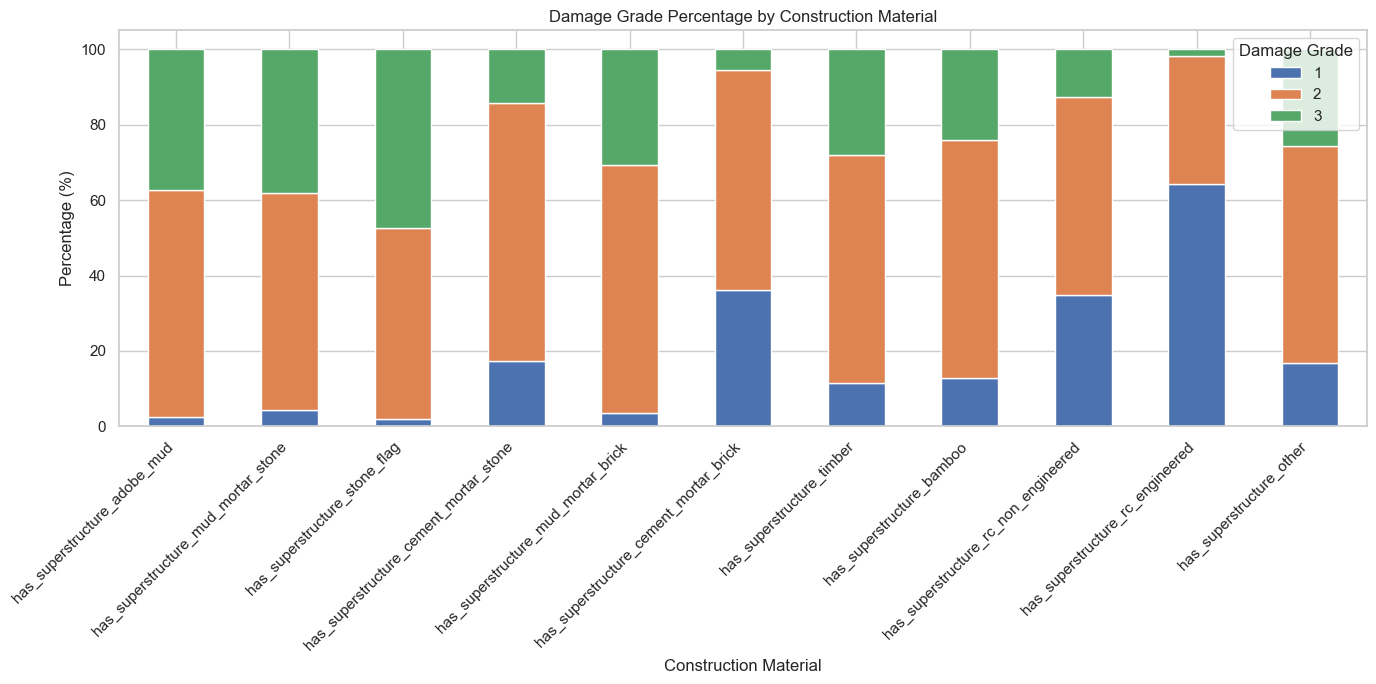

In [38]:
# Visualize construction material damage percentages

material_damage_df.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

plt.title('Damage Grade Percentage by Construction Material')
plt.xlabel('Construction Material')
plt.ylabel('Percentage (%)')

plt.legend(title='Damage Grade')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


### Construction Material Analysis – Observation

The analysis examined the distribution of construction
materials and their relationship with earthquake
damage grades.

The mud mortar stone feature was found to be the
most frequently occurring construction material,
followed by timber.

Most construction material categories showed
Grade 2 as the dominant damage category.

The reinforced concrete engineered feature showed
a comparatively higher proportion of Grade 1
observations in the percentage analysis.

These results suggest that construction material
features may provide useful predictive information.

However, the observed relationships are statistical
associations and do not establish causation.


### Geographical Damage Analysis

In [ ]:
# Analyze damage by geographical level 1

geo1_damage = pd.crosstab(
    df['geo_level_1_id'],
    df['damage_grade']
)

print("Geographical Level 1 Damage Distribution:")

display(geo1_damage.head(10))

# Visualize geographical damage distribution

geo1_damage.plot(
    kind='bar',
    stacked=True,
    figsize=(15, 6)
)

plt.title('Earthquake Damage Distribution by Geo Level 1')
plt.xlabel('Geo Level 1 ID')
plt.ylabel('Number of Buildings')

plt.legend(title='Damage Grade')
plt.show()

In [40]:
# Calculate damage percentages by geographical level 1

geo1_percentage = pd.crosstab(
    df['geo_level_1_id'],
    df['damage_grade'],
    normalize='index'
) * 100

print("Geographical Damage Percentage:")

display(geo1_percentage.round(2).head(10))

Geographical Damage Percentage:


damage_grade,1,2,3
geo_level_1_id,,,
0,8.40,76.66,14.93
1,15.22,73.49,11.29
2,9.13,65.52,25.35
3,3.25,60.34,36.41
4,3.58,76.63,19.79
5,16.58,74.87,8.55
6,8.65,66.54,24.82
7,5.44,59.35,35.21
8,3.43,44.62,51.95


In [41]:
# Rank geographical regions by Grade 3 percentage

severe_damage_regions = geo1_percentage.sort_values(
    by=3,
    ascending=False
)

print("Top 10 Regions by Grade 3 Damage Percentage:")

display(severe_damage_regions.head(10))

Top 10 Regions by Grade 3 Damage Percentage:


damage_grade,1,2,3
geo_level_1_id,,,
17,1.306560,17.938844,80.754596
18,2.257761,24.647225,73.095014
21,2.162670,39.337766,58.499563
8,3.427673,44.617400,51.954927
27,3.710501,47.933291,48.356208
28,0.000000,59.245283,40.754717
10,5.484850,54.834911,39.680239
11,4.695864,56.836983,38.467153
3,3.249337,60.344828,36.405836


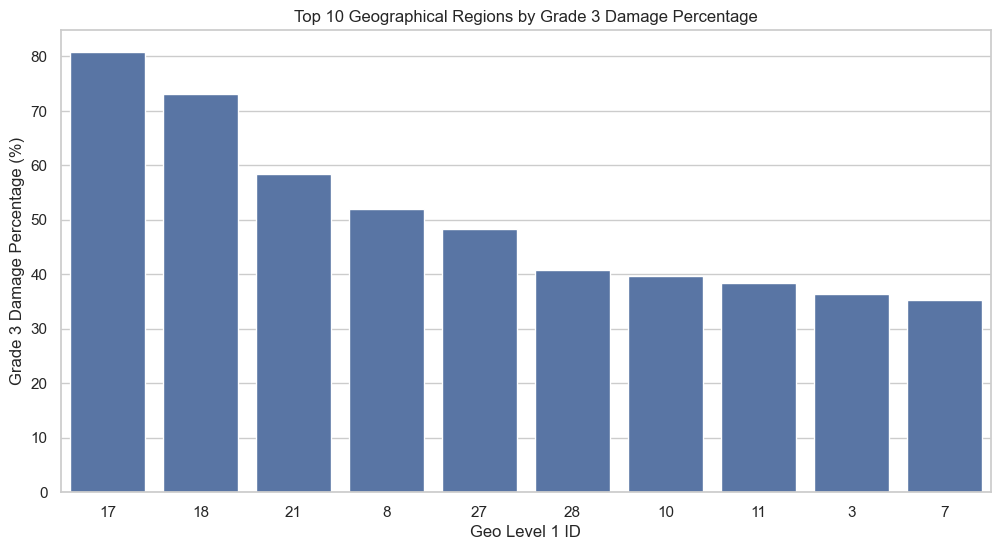

In [42]:
# Visualize top 10 regions with highest Grade 3 percentage

top_regions = severe_damage_regions.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_regions.index.astype(str),
    y=top_regions[3]
)

plt.title('Top 10 Geographical Regions by Grade 3 Damage Percentage')
plt.xlabel('Geo Level 1 ID')
plt.ylabel('Grade 3 Damage Percentage (%)')

plt.show()


### Geographical Damage Analysis – Observation

The geographical analysis was performed using the
geo_level_1_id feature.

The distribution of buildings varies across geographical
regions, and the damage-grade proportions are not uniform.

Region 17 recorded the highest Grade 3 damage proportion
at approximately 80.75%, followed by Region 18 at 73.10%.

Region 21 recorded approximately 58.50% Grade 3 damage.

These findings indicate that geographical information
may be an important predictive feature in earthquake
damage classification.

However, the results describe observed damage patterns
in the dataset and should not be interpreted as future
earthquake risk estimates.


### Statistical analysis

In [ ]:
# Select numerical features
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Remove building ID
numeric_df = numeric_df.drop(
    columns=['building_id'],
    errors='ignore'
)

# Calculate correlation
correlation_matrix = numeric_df.corr()

# Display correlation with damage grade
damage_correlation = (
    correlation_matrix['damage_grade']
    .sort_values(ascending=False)
)

print("Correlation with Damage Grade:")
display(damage_correlation)

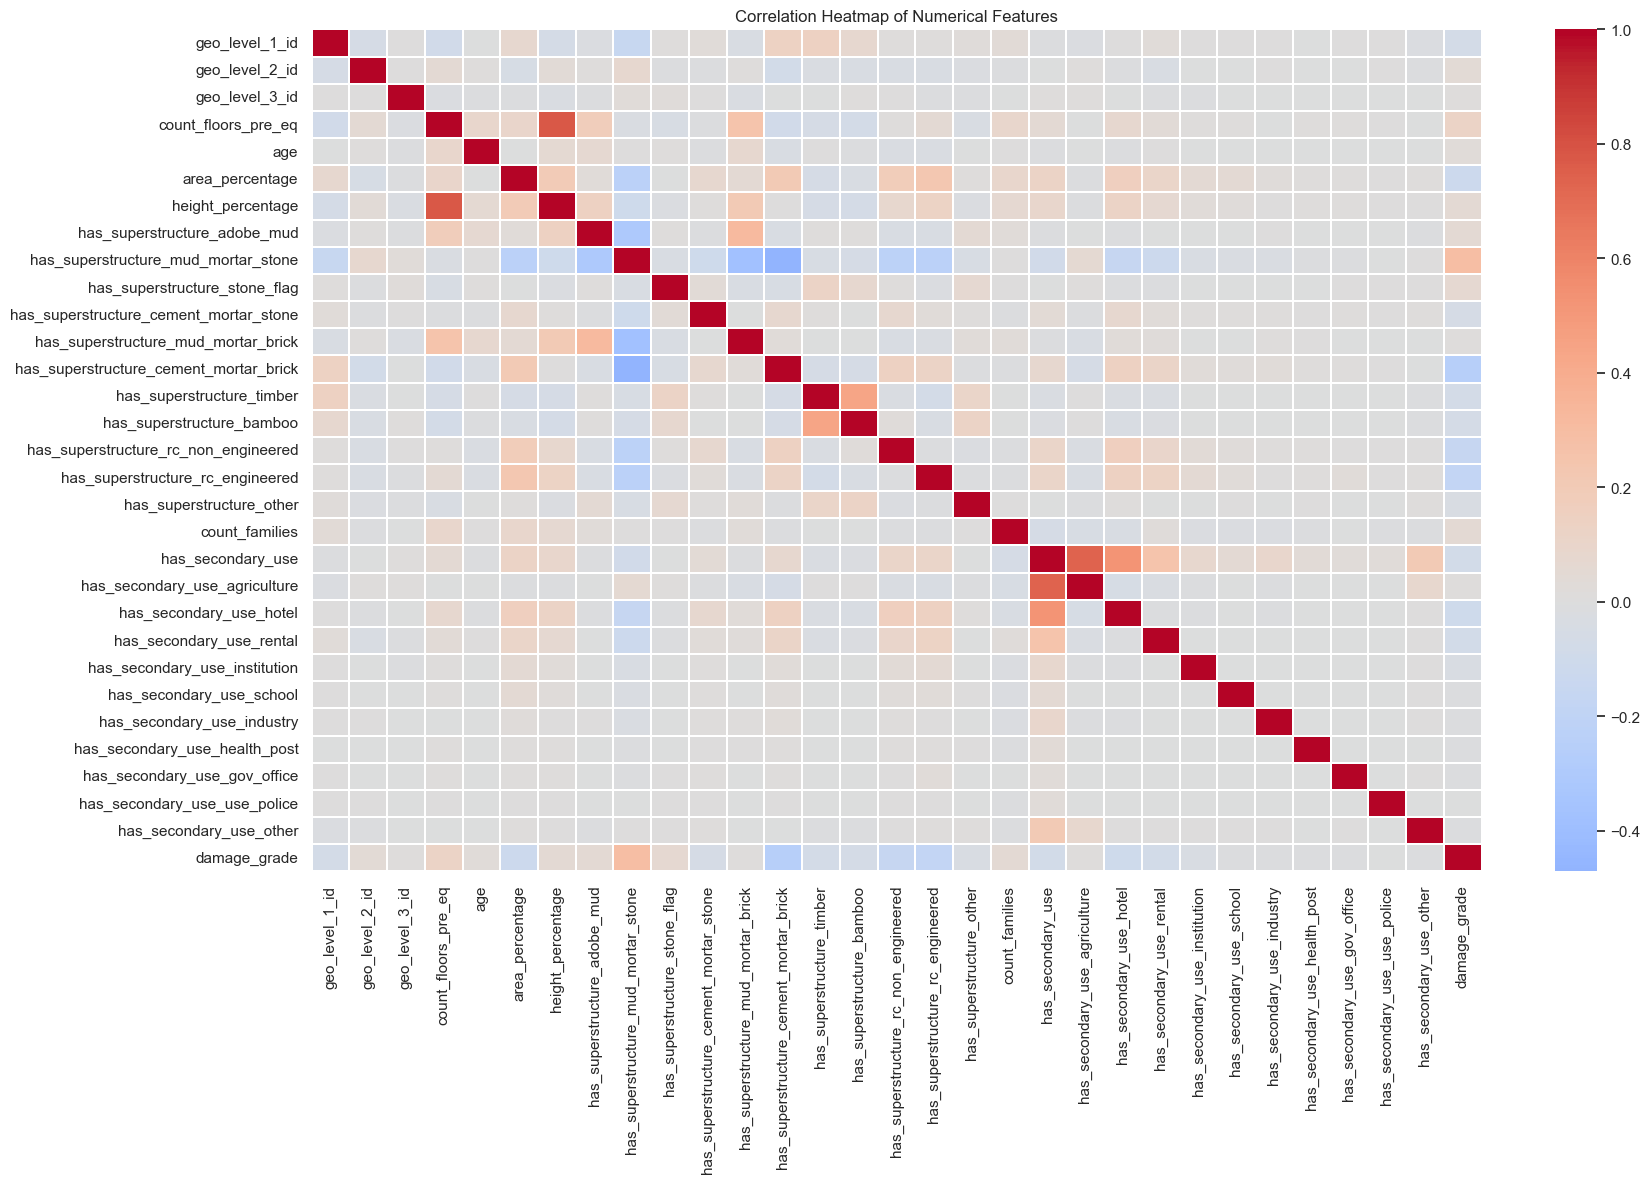

In [44]:
# Create correlation heatmap
plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.3
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

In [45]:
# Exclude the target itself
top_correlations = (
    damage_correlation
    .drop('damage_grade')
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Numerical Features by Absolute Correlation:")

display(top_correlations)

Top 10 Numerical Features by Absolute Correlation:


has_superstructure_mud_mortar_stone       0.291325
has_superstructure_cement_mortar_brick    0.254131
has_superstructure_rc_engineered          0.179014
has_superstructure_rc_non_engineered      0.158145
area_percentage                           0.125221
count_floors_pre_eq                       0.122308
has_secondary_use_hotel                   0.097942
has_secondary_use_rental                  0.083754
has_secondary_use                         0.079630
geo_level_1_id                            0.072347
Name: damage_grade, dtype: float64


### Correlation Analysis – Observation

Pearson correlation analysis was performed to examine
linear relationships between numerical features and
the target variable damage_grade.

The strongest positive correlation was observed for
has_superstructure_mud_mortar_stone (0.2913).

The strongest negative correlation was observed for
has_superstructure_cement_mortar_brick (-0.2541).

Other notable relationships included reinforced
concrete features, area percentage and building floors.

The heatmap also revealed relationships between
some input features.

Since damage_grade is a multiclass ordinal target,
Pearson correlation alone is insufficient to identify
all important predictive features.

Further feature selection will use statistical and
model-based methods.


### Categorical Feature Association Analysis

In [46]:
from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np

In [47]:
# Select categorical features
categorical_features = [
    'land_surface_condition',
    'foundation_type',
    'roof_type',
    'ground_floor_type',
    'other_floor_type',
    'position',
    'plan_configuration',
    'legal_ownership_status'
]

# Store statistical results
chi_results = []

for col in categorical_features:

    contingency_table = pd.crosstab(
        df[col],
        df['damage_grade']
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()

    # Cramer's V effect size
    min_dimension = min(contingency_table.shape) - 1

    cramers_v = np.sqrt(
        chi2 / (n * min_dimension)
    )

    chi_results.append({
        'Feature': col,
        'Chi-square': chi2,
        'P-value': p_value,
        'Cramers V': cramers_v
    })

chi_results_df = pd.DataFrame(chi_results)

chi_results_df = chi_results_df.sort_values(
    by='Cramers V',
    ascending=False
)

display(chi_results_df.round(4))

,Feature,Chi-square,P-value,Cramers V
1,foundation_type,48547.1607,0.0,0.3052
3,ground_floor_type,36430.8490,0.0,0.2644
4,other_floor_type,31487.3919,0.0,0.2458
2,roof_type,30251.4193,0.0,0.2409
7,legal_ownership_status,2586.1628,0.0,0.0704
6,plan_configuration,1734.1171,0.0,0.0577
5,position,1079.9274,0.0,0.0455
0,land_surface_condition,449.6714,0.0,0.0294


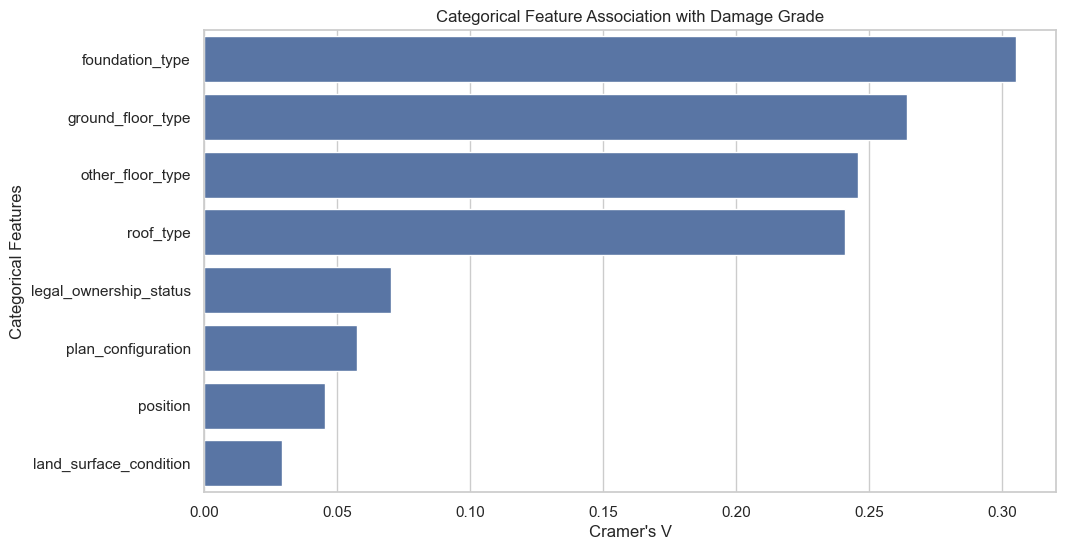

In [48]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=chi_results_df,
    x='Cramers V',
    y='Feature'
)

plt.title('Categorical Feature Association with Damage Grade')
plt.xlabel("Cramer's V")
plt.ylabel('Categorical Features')

plt.show()


### Chi-Square Test and Cramér's V – Observation

The Chi-square test was performed to examine the
association between categorical building features
and earthquake damage grades.

Cramér's V was calculated to measure the strength
of association.

Foundation type recorded the highest association
with a Cramér's V of 0.3052, followed by ground
floor type (0.2644), other floor type (0.2458)
and roof type (0.2409).

Legal ownership, plan configuration, position and
land surface condition showed comparatively weaker
associations.

The results suggest that structural categorical
features may provide useful predictive information.

These findings will guide further feature analysis,
but final feature selection will be based on
machine learning validation performance.


### Feature Engineering

In [49]:
# Create a copy of the original dataset
df_fe = df.copy()

# Calculate total superstructure materials
df_fe['total_superstructure_materials'] = (
    df_fe[material_columns].sum(axis=1)
)

# Calculate total secondary uses
secondary_columns = [
    col for col in df_fe.columns
    if col.startswith('has_secondary_use_')
    and col != 'has_secondary_use'
]

df_fe['total_secondary_uses'] = (
    df_fe[secondary_columns].sum(axis=1)
)

# Create building age category
df_fe['building_age_group'] = pd.cut(
    df_fe['age'],
    bins=[-1, 10, 30, 60, float('inf')],
    labels=['New', 'Medium', 'Old', 'Very Old']
)

# Display new features
display(
    df_fe[
        [
            'total_superstructure_materials',
            'total_secondary_uses',
            'building_age_group'
        ]
    ].head(10)
)

,total_superstructure_materials,total_secondary_uses,building_age_group
0,2,0,Medium
1,1,0,New
2,1,0,New
3,3,0,New
4,1,0,Medium
5,1,1,New
6,1,0,Medium
7,2,0,New
8,2,0,Medium
9,1,0,New


In [50]:
print("Original Dataset Shape:", df.shape)

print("Feature Engineered Dataset Shape:", df_fe.shape)

print("\nNew Feature Information:")

df_fe[
    [
        'total_superstructure_materials',
        'total_secondary_uses',
        'building_age_group'
    ]
].info()

Original Dataset Shape: (260601, 40)
Feature Engineered Dataset Shape: (260601, 43)

New Feature Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 3 columns):
 #   Column                          Non-Null Count   Dtype   
---  ------                          --------------   -----   
 0   total_superstructure_materials  260601 non-null  int64   
 1   total_secondary_uses            260601 non-null  int64   
 2   building_age_group              260601 non-null  category
dtypes: category(1), int64(2)
memory usage: 4.2 MB


### Data Preprocessing

In [51]:
# Separate input features and target variable

X = df_fe.drop(
    columns=['building_id', 'damage_grade']
)

y = df_fe['damage_grade']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Class Distribution:")
print(y.value_counts().sort_index())

Input Features Shape: (260601, 41)
Target Variable Shape: (260601,)

Target Class Distribution:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


In [52]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (208480, 41)
Testing Features: (52121, 41)
Training Target: (208480,)
Testing Target: (52121,)


### Categorical and Numerical Feature Identification

In [53]:
# Identify numerical columns
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Total Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Total Numerical Features: 32
Total Categorical Features: 9

Numerical Features:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other', 'total_superstructure_materials', 'total_secondary_uses']

Categ

In [54]:
print("Training Data Distribution:")
print(y_train.value_counts(normalize=True).sort_index() * 100)

print("\nTesting Data Distribution:")
print(y_test.value_counts(normalize=True).sort_index() * 100)

Training Data Distribution:
damage_grade
1     9.640733
2    56.891309
3    33.467959
Name: proportion, dtype: float64

Testing Data Distribution:
damage_grade
1     9.641028
2    56.890697
3    33.468276
Name: proportion, dtype: float64


### Encoding and Feature Scaling.

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [56]:
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created!")

Numerical preprocessing pipeline created!


In [57]:
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

print("Categorical preprocessing pipeline created!")

Categorical preprocessing pipeline created!


In [58]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Complete preprocessing system created!")

Complete preprocessing system created!


In [59]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using training-fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (208480, 74)
Testing data after preprocessing: (52121, 74)


### Correctly handle geographic features

In [60]:
geographic_features = [
    'geo_level_1_id',
    'geo_level_2_id',
    'geo_level_3_id'
]

for col in geographic_features:
    if col in numerical_features:
        numerical_features.remove(col)

    if col not in categorical_features:
        categorical_features.append(col)

print("Updated numerical features:", len(numerical_features))
print("Updated categorical features:", len(categorical_features))
print("\nGeographic features:", geographic_features)

Updated numerical features: 29
Updated categorical features: 12

Geographic features: ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']


### Rebuild the preprocessing pipeline

In [61]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Updated preprocessing pipeline created successfully!")

Updated preprocessing pipeline created successfully!


In [62]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Preprocessing completed successfully!")

Training data shape: (208480, 12891)
Testing data shape: (52121, 12891)
Preprocessing completed successfully!


In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Logistic Regression and evaluation tools imported!")

Logistic Regression and evaluation tools imported!


In [64]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model training completed!")

Logistic Regression model training completed!


In [65]:
y_pred_logistic = logistic_model.predict(X_test_processed)

accuracy = accuracy_score(y_test, y_pred_logistic)
macro_f1 = f1_score(y_test, y_pred_logistic, average='macro')

print("Logistic Regression Results")
print("----------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Macro F1 Score:", round(macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

Logistic Regression Results
----------------------------
Accuracy: 70.03 %
Macro F1 Score: 0.6755

Classification Report:
              precision    recall  f1-score   support

           1       0.45      0.85      0.59      5025
           2       0.81      0.64      0.72     29652
           3       0.69      0.75      0.72     17444

    accuracy                           0.70     52121
   macro avg       0.65      0.75      0.68     52121
weighted avg       0.74      0.70      0.71     52121


Confusion Matrix:
[[ 4293   618   114]
 [ 4683 19093  5876]
 [  543  3786 13115]]


In [66]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=25,
    min_samples_split=10,
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [67]:
y_pred_rf = random_forest_model.predict(X_test_processed)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_macro_f1 = f1_score(y_test, y_pred_rf, average='macro')

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Macro F1 Score:", round(rf_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results
---------------------
Accuracy: 60.76 %
Macro F1 Score: 0.5879

Classification Report:
              precision    recall  f1-score   support

           1       0.39      0.74      0.51      5025
           2       0.78      0.48      0.59     29652
           3       0.56      0.79      0.66     17444

    accuracy                           0.61     52121
   macro avg       0.58      0.67      0.59     52121
weighted avg       0.67      0.61      0.61     52121


Confusion Matrix:
[[ 3724  1025   276]
 [ 5027 14135 10490]
 [  713  2919 13812]]


In [68]:
from sklearn.ensemble import ExtraTreesClassifier

extra_trees_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=30,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

extra_trees_model.fit(X_train_processed, y_train)

print("Extra Trees training completed!")

Extra Trees training completed!


In [69]:
y_pred_et = extra_trees_model.predict(X_test_processed)

et_accuracy = accuracy_score(y_test, y_pred_et)
et_macro_f1 = f1_score(y_test, y_pred_et, average='macro')

print("Extra Trees Results")
print("-------------------")
print("Accuracy:", round(et_accuracy * 100, 2), "%")
print("Macro F1 Score:", round(et_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_et))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_et))

Extra Trees Results
-------------------
Accuracy: 62.37 %
Macro F1 Score: 0.6038

Classification Report:
              precision    recall  f1-score   support

           1       0.41      0.76      0.53      5025
           2       0.79      0.51      0.62     29652
           3       0.58      0.79      0.67     17444

    accuracy                           0.62     52121
   macro avg       0.59      0.68      0.60     52121
weighted avg       0.68      0.62      0.62     52121


Confusion Matrix:
[[ 3798  1004   223]
 [ 4883 15006  9763]
 [  638  3101 13705]]


In [70]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully!")

Logistic Regression pipeline created successfully!


In [71]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__solver': ['lbfgs'],
    'classifier__class_weight': ['balanced']
}

print("Hyperparameter grid:")
print(param_grid)

Hyperparameter grid:
{'classifier__C': [0.01, 0.1, 1, 10], 'classifier__solver': ['lbfgs'], 'classifier__class_weight': ['balanced']}


In [72]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("3-fold Stratified Cross-Validation configured!")

3-fold Stratified Cross-Validation configured!


### Hyperparameter tuning

In [73]:
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("\nHyperparameter tuning completed!")
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Macro F1:", round(grid_search.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits

Hyperparameter tuning completed!
Best Parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}
Best Cross-Validation Macro F1: 0.6645


In [74]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Macro F1:", round(grid_search.best_score_, 4))

Best Parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}
Best CV Macro F1: 0.6645


In [75]:
best_logistic_model = grid_search.best_estimator_

y_pred_tuned = best_logistic_model.predict(X_test)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_macro_f1 = f1_score(
    y_test,
    y_pred_tuned,
    average='macro'
)

print("Tuned Logistic Regression Results")
print("---------------------------------")
print("Accuracy:", round(tuned_accuracy * 100, 2), "%")
print("Macro F1:", round(tuned_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned Logistic Regression Results
---------------------------------
Accuracy: 70.03 %
Macro F1: 0.6755

Classification Report:
              precision    recall  f1-score   support

           1       0.45      0.85      0.59      5025
           2       0.81      0.64      0.72     29652
           3       0.69      0.75      0.72     17444

    accuracy                           0.70     52121
   macro avg       0.65      0.75      0.68     52121
weighted avg       0.74      0.70      0.71     52121


Confusion Matrix:
[[ 4293   618   114]
 [ 4683 19093  5876]
 [  543  3786 13115]]


In [76]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
    print("XGBoost is ready!")
except ImportError:
    print("XGBoost is not installed.")

XGBoost version: 3.4.1
XGBoost is ready!


In [77]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

print("XGBoost model configured successfully!")

XGBoost model configured successfully!


In [78]:
xgb_model.fit(X_train_processed, y_train - 1)

print("XGBoost training completed!")

XGBoost training completed!


In [79]:
y_pred_xgb = xgb_model.predict(X_test_processed) + 1

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

xgb_macro_f1 = f1_score(
    y_test,
    y_pred_xgb,
    average='macro'
)

print("XGBoost Results")
print("----------------")
print("Accuracy:", round(xgb_accuracy * 100, 2), "%")
print("Macro F1 Score:", round(xgb_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

XGBoost Results
----------------
Accuracy: 71.78 %
Macro F1 Score: 0.6469

Classification Report:
              precision    recall  f1-score   support

           1       0.69      0.43      0.53      5025
           2       0.71      0.87      0.78     29652
           3       0.76      0.55      0.64     17444

    accuracy                           0.72     52121
   macro avg       0.72      0.61      0.65     52121
weighted avg       0.72      0.72      0.71     52121


Confusion Matrix:
[[ 2139  2847    39]
 [  915 25680  3057]
 [   64  7786  9594]]


In [80]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train - 1
)

print("Sample weights created successfully!")
print("Sample weights shape:", sample_weights.shape)


Sample weights created successfully!
Sample weights shape: (208480,)


In [81]:
xgb_balanced_model = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_balanced_model.fit(
    X_train_processed,
    y_train - 1,
    sample_weight=sample_weights
)

print("Balanced XGBoost training completed!")

Balanced XGBoost training completed!


In [82]:
y_pred_xgb_balanced = (
    xgb_balanced_model.predict(X_test_processed) + 1
)

balanced_accuracy = accuracy_score(
    y_test,
    y_pred_xgb_balanced
)

balanced_macro_f1 = f1_score(
    y_test,
    y_pred_xgb_balanced,
    average='macro'
)

print("Balanced XGBoost Results")
print("------------------------")
print("Accuracy:", round(balanced_accuracy * 100, 2), "%")
print("Macro F1 Score:", round(balanced_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_balanced))

Balanced XGBoost Results
------------------------
Accuracy: 65.71 %
Macro F1 Score: 0.6333

Classification Report:
              precision    recall  f1-score   support

           1       0.41      0.82      0.55      5025
           2       0.77      0.59      0.67     29652
           3       0.65      0.72      0.68     17444

    accuracy                           0.66     52121
   macro avg       0.61      0.71      0.63     52121
weighted avg       0.70      0.66      0.66     52121


Confusion Matrix:
[[ 4112   819    94]
 [ 5244 17641  6767]
 [  634  4313 12497]]


In [83]:
model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Tuned Logistic Regression',
        'Random Forest',
        'Extra Trees',
        'XGBoost',
        'Balanced XGBoost'
    ],
    'Accuracy': [
        accuracy,
        tuned_accuracy,
        rf_accuracy,
        et_accuracy,
        xgb_accuracy,
        balanced_accuracy
    ],
    'Macro F1': [
        macro_f1,
        tuned_macro_f1,
        rf_macro_f1,
        et_macro_f1,
        xgb_macro_f1,
        balanced_macro_f1
    ]
})

model_results = model_results.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

print(model_results.round(4))

                       Model  Accuracy  Macro F1
0        Logistic Regression    0.7003    0.6755
1  Tuned Logistic Regression    0.7003    0.6755
2                    XGBoost    0.7178    0.6469
3           Balanced XGBoost    0.6571    0.6333
4                Extra Trees    0.6237    0.6038
5              Random Forest    0.6076    0.5879


In [84]:
best_model = grid_search.best_estimator_

feature_names = best_model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = best_model.named_steps[
    'classifier'
].coef_

for class_index, grade in enumerate([1, 2, 3]):
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Coefficient': coefficients[class_index],
        'Absolute Importance': abs(coefficients[class_index])
    })

    importance_df = importance_df.sort_values(
        by='Absolute Importance',
        ascending=False
    )

    print(f"\nTop 15 features for Damage Grade {grade}")
    display(importance_df.head(15))


Top 15 features for Damage Grade 1


,Feature,Coefficient,Absolute Importance
3114,cat__geo_level_3_id_1780,3.065285,3.065285
5433,cat__geo_level_3_id_4327,2.925985,2.925985
7670,cat__geo_level_3_id_6799,2.846785,2.846785
115,cat__geo_level_2_id_14,2.741883,2.741883
7667,cat__geo_level_3_id_6795,2.705112,2.705112
2340,cat__geo_level_3_id_913,-2.674598,2.674598
10903,cat__geo_level_3_id_10375,2.603688,2.603688
5111,cat__geo_level_3_id_3971,2.517546,2.517546
3098,cat__geo_level_3_id_1761,2.509893,2.509893
3883,cat__geo_level_3_id_2616,2.386656,2.386656



Top 15 features for Damage Grade 2


,Feature,Coefficient,Absolute Importance
356,cat__geo_level_2_id_258,-2.153032,2.153032
2475,cat__geo_level_3_id_1061,1.959674,1.959674
254,cat__geo_level_2_id_155,-1.857302,1.857302
6910,cat__geo_level_3_id_5957,-1.827326,1.827326
958,cat__geo_level_2_id_869,1.767509,1.767509
11581,cat__geo_level_3_id_11130,-1.749463,1.749463
5395,cat__geo_level_3_id_4285,-1.726934,1.726934
3654,cat__geo_level_3_id_2372,1.711043,1.711043
4922,cat__geo_level_3_id_3765,-1.674208,1.674208
768,cat__geo_level_2_id_676,-1.668660,1.668660



Top 15 features for Damage Grade 3


,Feature,Coefficient,Absolute Importance
88,cat__geo_level_1_id_17,2.438580,2.438580
5433,cat__geo_level_3_id_4327,-2.256669,2.256669
2340,cat__geo_level_3_id_913,2.197486,2.197486
11954,cat__geo_level_3_id_11548,2.147068,2.147068
139,cat__geo_level_2_id_38,2.129637,2.129637
545,cat__geo_level_2_id_451,-2.114808,2.114808
89,cat__geo_level_1_id_18,2.099777,2.099777
654,cat__geo_level_2_id_562,-2.039669,2.039669
3114,cat__geo_level_3_id_1780,-1.994945,1.994945
9953,cat__geo_level_3_id_9318,1.980683,1.980683


In [85]:
from sklearn.inspection import permutation_importance

# Use a manageable sample for faster computation
X_importance = X_test.sample(
    n=5000,
    random_state=42
)

y_importance = y_test.loc[X_importance.index]

# Calculate permutation importance
perm_result = permutation_importance(
    best_model,
    X_importance,
    y_importance,
    scoring='f1_macro',
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

# Create importance table
feature_importance = pd.DataFrame({
    'Feature': X_importance.columns,
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(20))

,Feature,Importance,Std
0,geo_level_1_id,0.132346,0.003827
1,geo_level_2_id,0.075776,0.002119
2,geo_level_3_id,0.061183,0.001653
3,has_secondary_use,0.004767,0.000825
4,other_floor_type,0.003131,0.001978
5,building_age_group,0.002749,0.001987
6,has_superstructure_mud_mortar_stone,0.002720,0.002245
7,total_superstructure_materials,0.002666,0.000972
8,has_superstructure_mud_mortar_brick,0.002375,0.000563
9,ground_floor_type,0.001994,0.000487


In [127]:

from sklearn.inspection import permutation_importance

# Select 5,000 samples from the geographic holdout dataset
X_importance = X_geo_test.drop(
    columns=geo_columns
).sample(
    n=5000,
    random_state=42
)

y_importance = y_geo_test.loc[X_importance.index]

# Calculate permutation importance using final Random Forest
perm_result = permutation_importance(
    final_rf_model,
    X_importance,
    y_importance,
    scoring='f1_macro',
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

# Create feature importance table
feature_importance = pd.DataFrame({
    'Feature': X_importance.columns,
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(20))


,Feature,Importance,Std
0,has_superstructure_mud_mortar_stone,0.009684,0.000858
1,total_superstructure_materials,0.008589,0.001831
2,foundation_type,0.006651,0.000644
3,has_superstructure_timber,0.006152,0.002353
4,has_superstructure_cement_mortar_brick,0.006028,0.001386
5,height_percentage,0.005596,0.000839
6,legal_ownership_status,0.002647,0.000615
7,has_superstructure_stone_flag,0.002552,0.001431
8,roof_type,0.001027,0.001574
9,has_superstructure_other,0.000230,0.000187


In [128]:
final_holdout_report = classification_report(
    y_geo_test,
    final_rf_predictions,
    output_dict=True
)

final_holdout_df = pd.DataFrame(
    final_holdout_report
).transpose()

display(final_holdout_df.round(4))

final_holdout_df.to_csv(
    "earthquake_final_holdout_report.csv"
)

print("Final holdout report saved successfully!")

,precision,recall,f1-score,support
1,0.2607,0.7808,0.3909,2208.0000
2,0.4314,0.4392,0.4353,23956.0000
3,0.6773,0.5838,0.6271,35056.0000
accuracy,0.5343,0.5343,0.5343,0.5343
macro avg,0.4565,0.6013,0.4844,61220.0000
weighted avg,0.5660,0.5343,0.5435,61220.0000


Final holdout report saved successfully!


In [129]:
import os

required_files = [
    "earthquake_final_holdout_report.csv"
]

for file in required_files:
    if os.path.exists(file):
        print("FOUND:", file)
    else:
        print("MISSING:", file)

FOUND: earthquake_final_holdout_report.csv


In [87]:
preprocessor_no_geo = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, num_features_no_geo),
        ('cat', categorical_transformer, cat_features_no_geo)
    ]
)

model_no_geo = Pipeline(steps=[
    ('preprocessor', preprocessor_no_geo),
    ('classifier', LogisticRegression(
        C=1,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

model_no_geo.fit(X_train_no_geo, y_train)

print("Model without geographic features trained!")

Model without geographic features trained!


In [88]:
y_pred_no_geo = model_no_geo.predict(X_test_no_geo)

no_geo_accuracy = accuracy_score(y_test, y_pred_no_geo)
no_geo_macro_f1 = f1_score(
    y_test,
    y_pred_no_geo,
    average='macro'
)

print("Logistic Regression Without Geography")
print("--------------------------------------")
print("Accuracy:", round(no_geo_accuracy * 100, 2), "%")
print("Macro F1:", round(no_geo_macro_f1, 4))

Logistic Regression Without Geography
--------------------------------------
Accuracy: 49.86 %
Macro F1: 0.4969


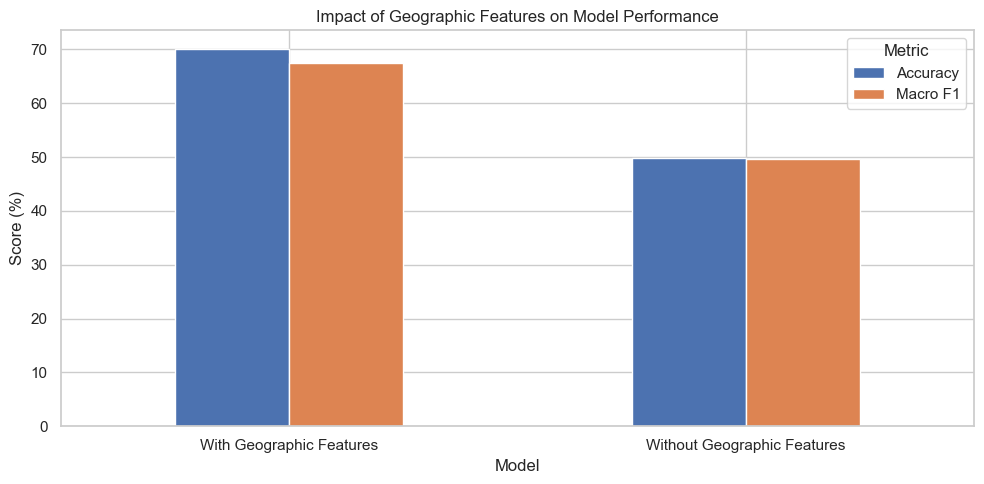

In [89]:
comparison_geo = pd.DataFrame({
    'Model': [
        'With Geographic Features',
        'Without Geographic Features'
    ],
    'Accuracy': [
        accuracy * 100,
        no_geo_accuracy * 100
    ],
    'Macro F1': [
        macro_f1 * 100,
        no_geo_macro_f1 * 100
    ]
})

comparison_geo.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Impact of Geographic Features on Model Performance')
plt.ylabel('Score (%)')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

In [90]:
print("Unique Level 1 regions:", df_fe['geo_level_1_id'].nunique())
print("Unique Level 2 regions:", df_fe['geo_level_2_id'].nunique())
print("Unique Level 3 regions:", df_fe['geo_level_3_id'].nunique())

print("\nBuildings per Level 1 region:")
display(
    df_fe['geo_level_1_id']
    .value_counts()
    .head(10)
)

Unique Level 1 regions: 31
Unique Level 2 regions: 1414
Unique Level 3 regions: 11595

Buildings per Level 1 region:


geo_level_1_id
6     24381
26    22615
10    22079
17    21813
8     19080
7     18994
20    17216
21    14889
4     14568
27    12532
Name: count, dtype: int64

In [91]:
from sklearn.model_selection import GroupShuffleSplit

geo_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, geo_test_idx = next(
    geo_split.split(
        X,
        y,
        groups=X['geo_level_1_id']
    )
)

X_geo_train = X.iloc[train_idx]
X_geo_test = X.iloc[geo_test_idx]

y_geo_train = y.iloc[train_idx]
y_geo_test = y.iloc[geo_test_idx]

print("Training shape:", X_geo_train.shape)
print("Testing shape:", X_geo_test.shape)

print("\nTraining regions:",
      X_geo_train['geo_level_1_id'].nunique())

print("Testing regions:",
      X_geo_test['geo_level_1_id'].nunique())

print("\nOverlapping regions:",
      len(set(X_geo_train['geo_level_1_id']) &
          set(X_geo_test['geo_level_1_id'])))

Training shape: (199381, 41)
Testing shape: (61220, 41)

Training regions: 24
Testing regions: 7

Overlapping regions: 0


In [92]:
geo_distribution = pd.DataFrame({
    'Training': y_geo_train.value_counts(normalize=True).sort_index() * 100,
    'Unseen Regions': y_geo_test.value_counts(normalize=True).sort_index() * 100
})

geo_distribution.index.name = 'Damage Grade'

print("Damage grade distribution (%)")
display(geo_distribution.round(2))

Damage grade distribution (%)


,Training,Unseen Regions
Damage Grade,,
1,11.49,3.61
2,62.34,39.13
3,26.16,57.26


In [93]:
geo_distribution = pd.DataFrame({
    'Training': y_geo_train.value_counts(normalize=True).sort_index() * 100,
    'Unseen Regions': y_geo_test.value_counts(normalize=True).sort_index() * 100
})

geo_distribution.index.name = 'Damage Grade'

display(geo_distribution.round(2))

,Training,Unseen Regions
Damage Grade,,
1,11.49,3.61
2,62.34,39.13
3,26.16,57.26


In [94]:
geo_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        C=1,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

geo_model.fit(X_geo_train, y_geo_train)

print("Geographic holdout model training completed!")

Geographic holdout model training completed!


In [96]:
y_geo_pred = geo_model.predict(X_geo_test)

geo_accuracy = accuracy_score(y_geo_test, y_geo_pred)
geo_macro_f1 = f1_score(
    y_geo_test,
    y_geo_pred,
    average='macro'
)

print("GEOGRAPHIC HOLDOUT RESULTS")
print("--------------------------")
print("Accuracy:", round(geo_accuracy * 100, 2), "%")
print("Macro F1:", round(geo_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_geo_test, y_geo_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_geo_test, y_geo_pred))

GEOGRAPHIC HOLDOUT RESULTS
--------------------------
Accuracy: 43.11 %
Macro F1: 0.4195

Classification Report:
              precision    recall  f1-score   support

           1       0.30      0.77      0.43      2208
           2       0.38      0.71      0.50     23956
           3       0.68      0.22      0.33     35056

    accuracy                           0.43     61220
   macro avg       0.45      0.57      0.42     61220
weighted avg       0.55      0.43      0.40     61220


Confusion Matrix:
[[ 1694   393   121]
 [ 3433 16926  3597]
 [  611 26671  7774]]


In [97]:
geo_model_no_location = Pipeline(steps=[
    ('preprocessor', preprocessor_no_geo),
    ('classifier', LogisticRegression(
        C=1,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

geo_model_no_location.fit(
    X_geo_train.drop(columns=geo_columns),
    y_geo_train
)

print("Geographic-independent model trained!")

Geographic-independent model trained!


In [98]:
X_geo_test_no_location = X_geo_test.drop(
    columns=geo_columns
)

y_geo_pred_no_location = geo_model_no_location.predict(
    X_geo_test_no_location
)

print("UNSEEN REGION RESULTS - WITHOUT GEOGRAPHY")
print("-----------------------------------------")

print(
    "Accuracy:",
    round(
        accuracy_score(y_geo_test, y_geo_pred_no_location) * 100,
        2
    ),
    "%"
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_geo_test,
            y_geo_pred_no_location,
            average='macro'
        ),
        4
    )
)

print("\nClassification Report:")
print(classification_report(y_geo_test, y_geo_pred_no_location))

print("\nConfusion Matrix:")
print(confusion_matrix(y_geo_test, y_geo_pred_no_location))

UNSEEN REGION RESULTS - WITHOUT GEOGRAPHY
-----------------------------------------
Accuracy: 55.99 %
Macro F1: 0.4767

Classification Report:
              precision    recall  f1-score   support

           1       0.24      0.80      0.37      2208
           2       0.45      0.30      0.36     23956
           3       0.67      0.72      0.69     35056

    accuracy                           0.56     61220
   macro avg       0.45      0.61      0.48     61220
weighted avg       0.57      0.56      0.55     61220


Confusion Matrix:
[[ 1777   188   243]
 [ 4303  7279 12374]
 [ 1198  8636 25222]]


In [99]:
xgb_geo_independent = Pipeline(steps=[
    ('preprocessor', preprocessor_no_geo),
    ('classifier', XGBClassifier(
        objective='multi:softprob',
        num_class=3,
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='mlogloss',
        random_state=42,
        n_jobs=-1
    ))
])

print("Geography-independent XGBoost created!")

Geography-independent XGBoost created!


In [100]:
xgb_geo_independent.fit(
    X_geo_train.drop(columns=geo_columns),
    y_geo_train - 1
)

print("Geography-independent XGBoost training completed!")

Geography-independent XGBoost training completed!


In [101]:
y_pred_geo_xgb = (
    xgb_geo_independent.predict(
        X_geo_test.drop(columns=geo_columns)
    ) + 1
)

print("XGBOOST - UNSEEN REGION RESULTS")
print("--------------------------------")
print(
    "Accuracy:",
    round(accuracy_score(y_geo_test, y_pred_geo_xgb) * 100, 2),
    "%"
)
print(
    "Macro F1:",
    round(f1_score(y_geo_test, y_pred_geo_xgb, average='macro'), 4)
)

print("\nClassification Report:")
print(classification_report(y_geo_test, y_pred_geo_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_geo_test, y_pred_geo_xgb))

XGBOOST - UNSEEN REGION RESULTS
--------------------------------
Accuracy: 40.61 %
Macro F1: 0.3732

Classification Report:
              precision    recall  f1-score   support

           1       0.41      0.55      0.47      2208
           2       0.39      0.91      0.55     23956
           3       0.72      0.06      0.10     35056

    accuracy                           0.41     61220
   macro avg       0.51      0.50      0.37     61220
weighted avg       0.58      0.41      0.29     61220


Confusion Matrix:
[[ 1215   975    18]
 [ 1520 21705   731]
 [  217 32897  1942]]


In [102]:
generalization_results = pd.DataFrame({
    'Model': [
        'Logistic Regression - Random Split',
        'Logistic Regression - Geographic Split',
        'Logistic Regression - Geographic Split Without Geo',
        'XGBoost - Geographic Split Without Geo'
    ],
    'Accuracy': [
        accuracy,
        geo_accuracy,
        no_geo_accuracy if False else accuracy_score(
            y_geo_test, y_geo_pred_no_location
        ),
        accuracy_score(y_geo_test, y_pred_geo_xgb)
    ],
    'Macro F1': [
        macro_f1,
        geo_macro_f1,
        f1_score(y_geo_test, y_geo_pred_no_location, average='macro'),
        f1_score(y_geo_test, y_pred_geo_xgb, average='macro')
    ]
})

display(
    generalization_results.sort_values(
        by='Macro F1',
        ascending=False
    ).round(4)
)

,Model,Accuracy,Macro F1
0,Logistic Regression - Random Split,0.7003,0.6755
2,Logistic Regression - Geographic Split Without...,0.5599,0.4767
1,Logistic Regression - Geographic Split,0.4311,0.4195
3,XGBoost - Geographic Split Without Geo,0.4061,0.3732


In [103]:
generalization_results.to_csv(
    "earthquake_model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


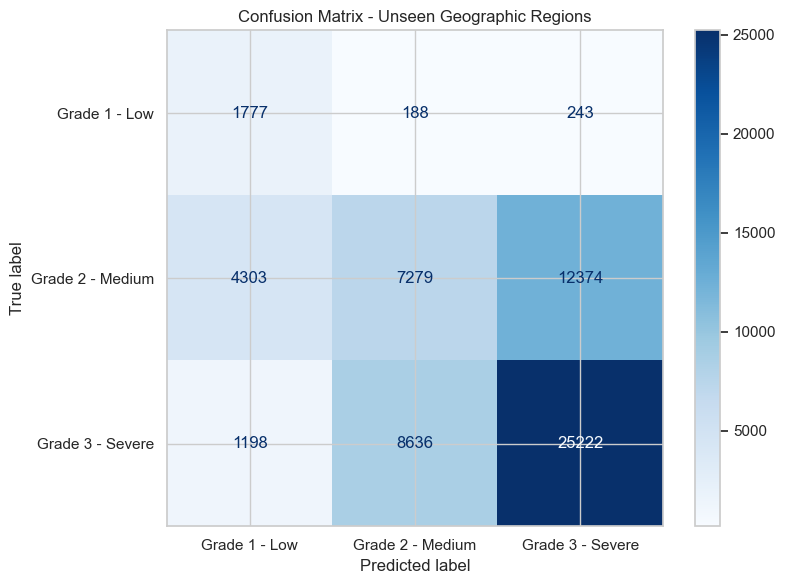

In [104]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_geo_test,
    y_geo_pred_no_location,
    display_labels=[
        'Grade 1 - Low',
        'Grade 2 - Medium',
        'Grade 3 - Severe'
    ],
    cmap='Blues',
    values_format='d',
    ax=ax
)

plt.title('Confusion Matrix - Unseen Geographic Regions')
plt.tight_layout()
plt.show()

In [105]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# Predict probabilities
y_geo_prob = geo_model_no_location.predict_proba(
    X_geo_test_no_location
)

# Convert actual labels into binary format
y_geo_binary = label_binarize(
    y_geo_test,
    classes=[1, 2, 3]
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_geo_binary,
    y_geo_prob,
    multi_class='ovr',
    average='macro'
)

print("Multiclass ROC-AUC:", round(roc_auc, 4))

Multiclass ROC-AUC: 0.6925


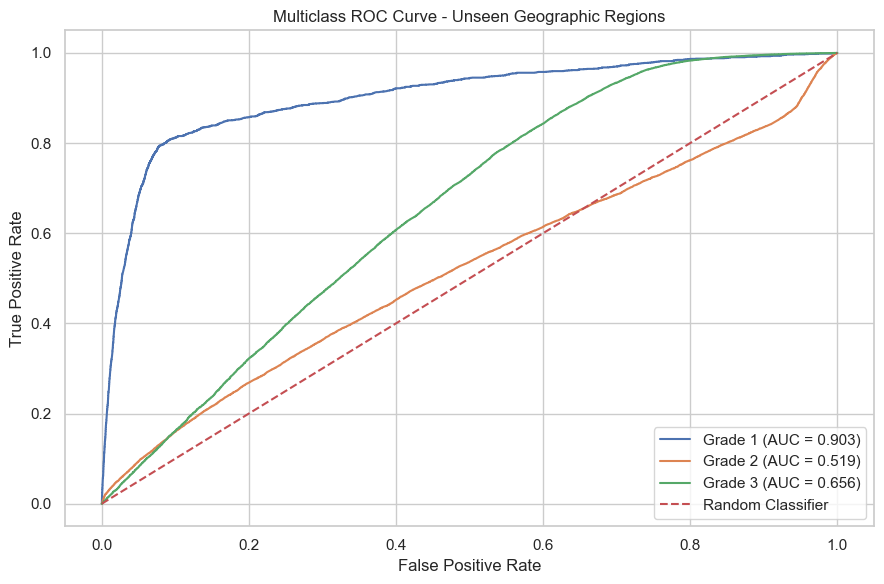

In [106]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

classes = [1, 2, 3]

y_binary = label_binarize(
    y_geo_test,
    classes=classes
)

plt.figure(figsize=(9, 6))

for i, grade in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(
        y_binary[:, i],
        y_geo_prob[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'Grade {grade} (AUC = {class_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('Multiclass ROC Curve - Unseen Geographic Regions')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [107]:
plt.savefig(
    'earthquake_multiclass_roc_curve.png',
    dpi=300,
    bbox_inches='tight'
)

print("ROC curve saved successfully!")

ROC curve saved successfully!


In [108]:
from sklearn.model_selection import GroupShuffleSplit

grade2_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=21
)

grade2_train_idx, grade2_val_idx = next(
    grade2_split.split(
        X_geo_train,
        y_geo_train,
        groups=X_geo_train['geo_level_1_id']
    )
)

X_g2_train = X_geo_train.iloc[grade2_train_idx].drop(
    columns=geo_columns
)

X_g2_val = X_geo_train.iloc[grade2_val_idx].drop(
    columns=geo_columns
)

y_g2_train = y_geo_train.iloc[grade2_train_idx]
y_g2_val = y_geo_train.iloc[grade2_val_idx]

print("Training shape:", X_g2_train.shape)
print("Validation shape:", X_g2_val.shape)

print("\nTraining regions:",
      X_geo_train.iloc[grade2_train_idx]['geo_level_1_id'].nunique())

print("Validation regions:",
      X_geo_train.iloc[grade2_val_idx]['geo_level_1_id'].nunique())

print("Overlapping regions:",
      len(set(X_geo_train.iloc[grade2_train_idx]['geo_level_1_id']) &
          set(X_geo_train.iloc[grade2_val_idx]['geo_level_1_id'])))

Training shape: (155775, 38)
Validation shape: (43606, 38)

Training regions: 19
Validation regions: 5
Overlapping regions: 0


In [109]:
grade2_distribution = pd.DataFrame({
    'Training': (
        y_g2_train.value_counts(normalize=True).sort_index() * 100
    ),
    'Validation': (
        y_g2_val.value_counts(normalize=True).sort_index() * 100
    )
})

grade2_distribution.index.name = 'Damage Grade'

display(grade2_distribution.round(2))

,Training,Validation
Damage Grade,,
1,13.16,5.53
2,64.19,55.77
3,22.65,38.70


In [110]:
print("Training shape:", X_g2_train.shape)
print("Validation shape:", X_g2_val.shape)

print("\nClass distribution:")
display(grade2_distribution.round(2))

print("\nOverlapping geographic regions:",
      len(set(X_geo_train.iloc[grade2_train_idx]['geo_level_1_id']) &
          set(X_geo_train.iloc[grade2_val_idx]['geo_level_1_id'])))

Training shape: (155775, 38)
Validation shape: (43606, 38)

Class distribution:


,Training,Validation
Damage Grade,,
1,13.16,5.53
2,64.19,55.77
3,22.65,38.70



Overlapping geographic regions: 0


In [111]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

grade2_weights = [
    {1: 1, 2: 1,    3: 1},
    {1: 1, 2: 1.25, 3: 1},
    {1: 1, 2: 1.5,  3: 1},
    {1: 1, 2: 2,    3: 1}
]

grade2_experiments = []

for weights in grade2_weights:

    model = Pipeline(steps=[
        ('preprocessor', preprocessor_no_geo),
        ('classifier', LogisticRegression(
            C=1,
            max_iter=1000,
            class_weight=weights,
            random_state=42
        ))
    ])

    model.fit(X_g2_train, y_g2_train)

    predictions = model.predict(X_g2_val)

    grade2_experiments.append({
        'Grade 2 Weight': weights[2],
        'Accuracy': accuracy_score(y_g2_val, predictions),
        'Macro F1': f1_score(
            y_g2_val, predictions, average='macro'
        ),
        'Grade 2 Precision': precision_score(
            y_g2_val, predictions, labels=[2],
            average='macro', zero_division=0
        ),
        'Grade 2 Recall': recall_score(
            y_g2_val, predictions, labels=[2],
            average='macro', zero_division=0
        )
    })

grade2_results = pd.DataFrame(grade2_experiments)

display(
    grade2_results.sort_values(
        by='Macro F1',
        ascending=False
    ).round(4)
)

,Grade 2 Weight,Accuracy,Macro F1,Grade 2 Precision,Grade 2 Recall
0,1.00,0.5615,0.3761,0.5630,0.9695
1,1.25,0.5614,0.3581,0.5618,0.9786
2,1.50,0.5600,0.3390,0.5606,0.9829
3,2.00,0.5587,0.3064,0.5591,0.9892


Classification Report:
              precision    recall  f1-score   support

           1     0.5166    0.3296    0.4024      2412
           2     0.5630    0.9695    0.7123     24317
           3     0.5990    0.0068    0.0135     16877

    accuracy                         0.5615     43606
   macro avg     0.5595    0.4353    0.3761     43606
weighted avg     0.5743    0.5615    0.4247     43606



<Figure size 640x480 with 0 Axes>

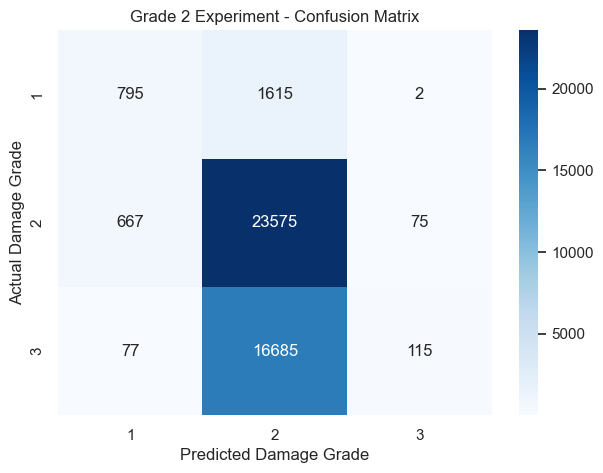

In [112]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

best_grade2_model = Pipeline(steps=[
    ('preprocessor', preprocessor_no_geo),
    ('classifier', LogisticRegression(
        C=1,
        max_iter=1000,
        class_weight={1: 1, 2: 1, 3: 1},
        random_state=42
    ))
])

best_grade2_model.fit(X_g2_train, y_g2_train)

best_predictions = best_grade2_model.predict(X_g2_val)

print("Classification Report:")
print(classification_report(
    y_g2_val,
    best_predictions,
    digits=4
))

cm = confusion_matrix(y_g2_val, best_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[1, 2, 3],
    yticklabels=[1, 2, 3]
)

plt.xlabel("Predicted Damage Grade")
plt.ylabel("Actual Damage Grade")
plt.title("Grade 2 Experiment - Confusion Matrix")
plt.show()

In [113]:
balanced_grade_model = Pipeline(steps=[
    ('preprocessor', preprocessor_no_geo),
    ('classifier', LogisticRegression(
        C=1,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

balanced_grade_model.fit(X_g2_train, y_g2_train)

balanced_predictions = balanced_grade_model.predict(X_g2_val)

print("Balanced Model Classification Report:")
print(classification_report(
    y_g2_val,
    balanced_predictions,
    digits=4
))

print("Macro F1:",
      f1_score(y_g2_val, balanced_predictions, average='macro'))

print("Confusion Matrix:")
print(confusion_matrix(y_g2_val, balanced_predictions))


Balanced Model Classification Report:
              precision    recall  f1-score   support

           1     0.3081    0.4797    0.3752      2412
           2     0.6524    0.2987    0.4098     24317
           3     0.4499    0.7654    0.5667     16877

    accuracy                         0.4894     43606
   macro avg     0.4701    0.5146    0.4506     43606
weighted avg     0.5549    0.4894    0.4686     43606

Macro F1: 0.4505608067063031
Confusion Matrix:
[[ 1157   458   797]
 [ 2052  7264 15001]
 [  546  3413 12918]]


In [114]:
grade_model_comparison = pd.DataFrame([
    {
        'Model': 'Equal Class Weights',
        'Accuracy': accuracy_score(y_g2_val, best_predictions),
        'Macro F1': f1_score(y_g2_val, best_predictions, average='macro'),
        'Grade 1 Recall': recall_score(y_g2_val, best_predictions, labels=[1], average='macro'),
        'Grade 2 Recall': recall_score(y_g2_val, best_predictions, labels=[2], average='macro'),
        'Grade 3 Recall': recall_score(y_g2_val, best_predictions, labels=[3], average='macro')
    },
    {
        'Model': 'Balanced Class Weights',
        'Accuracy': accuracy_score(y_g2_val, balanced_predictions),
        'Macro F1': f1_score(y_g2_val, balanced_predictions, average='macro'),
        'Grade 1 Recall': recall_score(y_g2_val, balanced_predictions, labels=[1], average='macro'),
        'Grade 2 Recall': recall_score(y_g2_val, balanced_predictions, labels=[2], average='macro'),
        'Grade 3 Recall': recall_score(y_g2_val, balanced_predictions, labels=[3], average='macro')
    }
])

display(
    grade_model_comparison
    .sort_values('Macro F1', ascending=False)
    .round(4)
)

,Model,Accuracy,Macro F1,Grade 1 Recall,Grade 2 Recall,Grade 3 Recall
1,Balanced Class Weights,0.4894,0.4506,0.4797,0.2987,0.7654
0,Equal Class Weights,0.5615,0.3761,0.3296,0.9695,0.0068


In [115]:
from sklearn.base import clone

c_values = [0.1, 0.5, 1, 2, 5]
tuning_results = []

for c in c_values:
    model = Pipeline(steps=[
        ('preprocessor', clone(preprocessor_no_geo)),
        ('classifier', LogisticRegression(
            C=c,
            max_iter=1000,
            class_weight='balanced',
            random_state=42
        ))
    ])

    model.fit(X_g2_train, y_g2_train)
    predictions = model.predict(X_g2_val)

    tuning_results.append({
        'C': c,
        'Accuracy': accuracy_score(y_g2_val, predictions),
        'Macro F1': f1_score(
            y_g2_val, predictions, average='macro'
        ),
        'Grade 1 Recall': recall_score(
            y_g2_val, predictions, labels=[1], average='macro'
        ),
        'Grade 2 Recall': recall_score(
            y_g2_val, predictions, labels=[2], average='macro'
        ),
        'Grade 3 Recall': recall_score(
            y_g2_val, predictions, labels=[3], average='macro'
        )
    })

tuning_table = pd.DataFrame(tuning_results)
display(tuning_table.sort_values('Macro F1', ascending=False).round(4))

,C,Accuracy,Macro F1,Grade 1 Recall,Grade 2 Recall,Grade 3 Recall
3,2.0,0.4894,0.4509,0.4797,0.2984,0.7660
4,5.0,0.4894,0.4507,0.4797,0.2977,0.7669
0,0.1,0.4892,0.4506,0.4797,0.2972,0.7671
2,1.0,0.4894,0.4506,0.4797,0.2987,0.7654
1,0.5,0.4890,0.4503,0.4797,0.2970,0.7670


In [116]:
best_c_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor_no_geo)),
    ('classifier', LogisticRegression(
        C=2.0,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

best_c_model.fit(X_g2_train, y_g2_train)

best_c_predictions = best_c_model.predict(X_g2_val)

prediction_distribution = pd.DataFrame({
    'Actual Count': y_g2_val.value_counts().sort_index(),
    'Predicted Count': pd.Series(best_c_predictions).value_counts().sort_index()
})

prediction_distribution.index.name = 'Damage Grade'

display(prediction_distribution)

,Actual Count,Predicted Count
Damage Grade,,
1,2412,3737
2,24317,11126
3,16877,28743


In [117]:
from sklearn.ensemble import RandomForestClassifier

rf_geo_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor_no_geo)),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=25,
        min_samples_split=10,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_geo_model.fit(X_g2_train, y_g2_train)

rf_geo_predictions = rf_geo_model.predict(X_g2_val)

print("Random Forest Classification Report:")
print(classification_report(
    y_g2_val,
    rf_geo_predictions,
    digits=4
))

print("Random Forest Macro F1:",
      f1_score(y_g2_val, rf_geo_predictions, average='macro'))

print("Confusion Matrix:")
print(confusion_matrix(y_g2_val, rf_geo_predictions))

Random Forest Classification Report:
              precision    recall  f1-score   support

           1     0.3230    0.4693    0.3826      2412
           2     0.6212    0.4578    0.5271     24317
           3     0.4582    0.6022    0.5204     16877

    accuracy                         0.5143     43606
   macro avg     0.4675    0.5098    0.4767     43606
weighted avg     0.5416    0.5143    0.5166     43606

Random Forest Macro F1: 0.4767338974540604
Confusion Matrix:
[[ 1132   664   616]
 [ 1784 11133 11400]
 [  589  6125 10163]]


In [118]:
from sklearn.ensemble import ExtraTreesClassifier

et_geo_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor_no_geo)),
    ('classifier', ExtraTreesClassifier(
        n_estimators=200,
        max_depth=30,
        min_samples_split=10,
        min_samples_leaf=2,
        max_features='sqrt',
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

et_geo_model.fit(X_g2_train, y_g2_train)

et_geo_predictions = et_geo_model.predict(X_g2_val)

print("Extra Trees Classification Report:")
print(classification_report(
    y_g2_val,
    et_geo_predictions,
    digits=4
))

print("Extra Trees Macro F1:",
      f1_score(y_g2_val, et_geo_predictions, average='macro'))

print("Confusion Matrix:")
print(confusion_matrix(y_g2_val, et_geo_predictions))

Extra Trees Classification Report:
              precision    recall  f1-score   support

           1     0.3039    0.4789    0.3718      2412
           2     0.6238    0.3600    0.4565     24317
           3     0.4471    0.6826    0.5403     16877

    accuracy                         0.4914     43606
   macro avg     0.4582    0.5072    0.4562     43606
weighted avg     0.5377    0.4914    0.4843     43606

Extra Trees Macro F1: 0.45620144993368755
Confusion Matrix:
[[ 1155   558   699]
 [ 2012  8754 13551]
 [  634  4722 11521]]


In [119]:
geo_model_comparison = pd.DataFrame([
    {
        'Model': 'Balanced Logistic Regression (C=2)',
        'Accuracy': accuracy_score(y_g2_val, best_c_predictions),
        'Macro F1': f1_score(y_g2_val, best_c_predictions, average='macro'),
        'Grade 1 Recall': recall_score(y_g2_val, best_c_predictions, labels=[1], average='macro'),
        'Grade 2 Recall': recall_score(y_g2_val, best_c_predictions, labels=[2], average='macro'),
        'Grade 3 Recall': recall_score(y_g2_val, best_c_predictions, labels=[3], average='macro')
    },
    {
        'Model': 'Random Forest',
        'Accuracy': accuracy_score(y_g2_val, rf_geo_predictions),
        'Macro F1': f1_score(y_g2_val, rf_geo_predictions, average='macro'),
        'Grade 1 Recall': recall_score(y_g2_val, rf_geo_predictions, labels=[1], average='macro'),
        'Grade 2 Recall': recall_score(y_g2_val, rf_geo_predictions, labels=[2], average='macro'),
        'Grade 3 Recall': recall_score(y_g2_val, rf_geo_predictions, labels=[3], average='macro')
    },
    {
        'Model': 'Extra Trees',
        'Accuracy': accuracy_score(y_g2_val, et_geo_predictions),
        'Macro F1': f1_score(y_g2_val, et_geo_predictions, average='macro'),
        'Grade 1 Recall': recall_score(y_g2_val, et_geo_predictions, labels=[1], average='macro'),
        'Grade 2 Recall': recall_score(y_g2_val, et_geo_predictions, labels=[2], average='macro'),
        'Grade 3 Recall': recall_score(y_g2_val, et_geo_predictions, labels=[3], average='macro')
    }
])

display(
    geo_model_comparison
    .sort_values('Macro F1', ascending=False)
    .round(4)
)

,Model,Accuracy,Macro F1,Grade 1 Recall,Grade 2 Recall,Grade 3 Recall
1,Random Forest,0.5143,0.4767,0.4693,0.4578,0.6022
2,Extra Trees,0.4914,0.4562,0.4789,0.3600,0.6826
0,Balanced Logistic Regression (C=2),0.4894,0.4509,0.4797,0.2984,0.7660


In [120]:
geo_model_comparison.to_csv(
    "earthquake_geographic_model_comparison.csv",
    index=False
)

print("Geographic model comparison saved successfully.")

Geographic model comparison saved successfully.


In [122]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

rf_cv_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor_no_geo)),
    ('classifier', RandomForestClassifier(
        n_estimators=150,
        max_depth=25,
        min_samples_split=10,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

group_cv = GroupKFold(n_splits=5)

cv_results = cross_validate(
    rf_cv_model,
    X_geo_train.drop(columns=geo_columns),
    y_geo_train,
    groups=X_geo_train['geo_level_1_id'],
    cv=group_cv,
    scoring={
        'accuracy': 'accuracy',
        'macro_f1': 'f1_macro'
    },
    n_jobs=1,
    return_train_score=False
)

print("Fold Accuracy:", cv_results['test_accuracy'])
print("Fold Macro F1:", cv_results['test_macro_f1'])

print("\nMean Accuracy:",
      cv_results['test_accuracy'].mean())

print("Mean Macro F1:",
      cv_results['test_macro_f1'].mean())

Fold Accuracy: [0.53290781 0.54499283 0.48040344 0.4820075  0.51100134]
Fold Macro F1: [0.51905191 0.49609872 0.44901614 0.44294433 0.49173765]

Mean Accuracy: 0.5102625853183209
Mean Macro F1: 0.47976975018707313


In [123]:
from sklearn.model_selection import cross_validate

class_cv_results = cross_validate(
    rf_cv_model,
    X_geo_train.drop(columns=geo_columns),
    y_geo_train,
    groups=X_geo_train['geo_level_1_id'],
    cv=group_cv,
    scoring={
        'grade1_f1': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    n_jobs=1
)

print("Mean Precision:", class_cv_results['test_precision_macro'].mean())
print("Mean Recall:", class_cv_results['test_recall_macro'].mean())
print("Mean F1:", class_cv_results['test_grade1_f1'].mean())

Mean Precision: 0.4797833460592821
Mean Recall: 0.5183900993822838
Mean F1: 0.47976975018707313


In [124]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

rf_oof_predictions = cross_val_predict(
    rf_cv_model,
    X_geo_train.drop(columns=geo_columns),
    y_geo_train,
    groups=X_geo_train['geo_level_1_id'],
    cv=group_cv,
    n_jobs=1
)

print("Geographic Cross-Validation Classification Report:")
print(classification_report(
    y_geo_train,
    rf_oof_predictions,
    digits=4
))

Geographic Cross-Validation Classification Report:
              precision    recall  f1-score   support

           1     0.4227    0.5791    0.4887     22916
           2     0.6798    0.4914    0.5705    124303
           3     0.3505    0.5250    0.4204     52162

    accuracy                         0.5103    199381
   macro avg     0.4844    0.5318    0.4932    199381
weighted avg     0.5641    0.5103    0.5218    199381



In [125]:
from sklearn.metrics import classification_report
import pandas as pd

final_cv_report = classification_report(
    y_geo_train,
    rf_oof_predictions,
    output_dict=True
)

final_cv_df = pd.DataFrame(final_cv_report).transpose()

display(final_cv_df.round(4))

final_cv_df.to_csv(
    "earthquake_final_geographic_cv_report.csv"
)

print("Final geographic CV report saved successfully!")

,precision,recall,f1-score,support
1,0.4227,0.5791,0.4887,22916.0000
2,0.6798,0.4914,0.5705,124303.0000
3,0.3505,0.5250,0.4204,52162.0000
accuracy,0.5103,0.5103,0.5103,0.5103
macro avg,0.4844,0.5318,0.4932,199381.0000
weighted avg,0.5641,0.5103,0.5218,199381.0000


Final geographic CV report saved successfully!


In [126]:
final_rf_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor_no_geo)),
    ('classifier', RandomForestClassifier(
        n_estimators=150,
        max_depth=25,
        min_samples_split=10,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

final_rf_model.fit(
    X_geo_train.drop(columns=geo_columns),
    y_geo_train
)

final_rf_predictions = final_rf_model.predict(
    X_geo_test.drop(columns=geo_columns)
)

print("Final Geographic Holdout Classification Report:")
print(classification_report(
    y_geo_test,
    final_rf_predictions,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_geo_test,
    final_rf_predictions
))

Final Geographic Holdout Classification Report:
              precision    recall  f1-score   support

           1     0.2607    0.7808    0.3909      2208
           2     0.4314    0.4392    0.4353     23956
           3     0.6773    0.5838    0.6271     35056

    accuracy                         0.5343     61220
   macro avg     0.4565    0.6013    0.4844     61220
weighted avg     0.5660    0.5343    0.5435     61220

Confusion Matrix:
[[ 1724   302   182]
 [ 3864 10522  9570]
 [ 1025 13566 20465]]


# DATA ANALYSIS REPORT – EARTHQUAKE DAMAGE PREDICTION

## 1. Introduction

The objective of this project is to analyze building characteristics and predict the extent of damage caused by earthquakes. The dataset contains information about buildings affected by the Gorkha earthquake.

The target variable, `damage_grade`, has three categories:

- Grade 1: Low damage
- Grade 2: Medium damage
- Grade 3: Almost complete destruction

## 2. Dataset Overview

The training dataset contains 260,601 building records and 39 input columns. After combining the building information with the target labels, the dataset contains 40 columns.

The `building_id` column uniquely identifies each building and was excluded from model training.

## 3. Data Quality Analysis

The following checks were performed:

- Missing value analysis.
- Duplicate record identification.
- Duplicate building ID verification.
- Data type inspection.
- Descriptive statistical analysis.
- Outlier investigation using the Interquartile Range (IQR) method.

No missing values or duplicate records were identified in the dataset.

Potential outliers were investigated in numerical features such as building age, number of floors, building area, height and number of families. Extreme values were not automatically removed because they may represent genuine building characteristics.

## 4. Target Variable Distribution

The target variable contains three damage categories:

| Damage Grade | Number of Buildings | Percentage |
|---|---:|---:|
| Grade 1 | 25,124 | 9.64% |
| Grade 2 | 148,259 | 56.89% |
| Grade 3 | 87,218 | 33.47% |

Grade 2 is the majority class, while Grade 1 is the minority class. This class imbalance was considered during model development.

## 5. Exploratory Data Analysis

The following analyses were performed:

- Distribution of building age and structural characteristics.
- Damage distribution across foundation types.
- Roof and ground-floor material analysis.
- Superstructure material analysis.
- Geographic damage distribution.
- Correlation analysis.
- Chi-square testing and Cramér's V association analysis.

The analysis showed differences in damage distributions across building characteristics and geographic regions.

## 6. Important Findings

### 6.1 Building Characteristics

Building age, foundation type, ground-floor type, roof type and structural materials showed different damage patterns.

The median building age increased across damage grades in the observed dataset, although the distributions overlapped.

### 6.2 Structural Materials

Pearson correlation analysis showed the following associations with the ordinal damage grade:

- Mud mortar stone: +0.2913
- Cement mortar brick: -0.2541
- RC engineered: -0.1790
- RC non-engineered: -0.1581

These values indicate linear associations, not causal relationships.

### 6.3 Categorical Feature Association

Cramér's V analysis identified the following associations:

| Feature | Cramér's V |
|---|---:|
| Foundation type | 0.3052 |
| Ground-floor type | 0.2644 |
| Other-floor type | 0.2458 |
| Roof type | 0.2409 |
| Legal ownership | 0.0704 |
| Plan configuration | 0.0577 |
| Position | 0.0455 |
| Land surface condition | 0.0294 |

Foundation type showed the strongest association among these analyzed categorical variables.

### 6.4 Geographic Analysis

Geographic regions showed considerable differences in damage distribution. For example, Grade 3 represented 80.75% of the buildings in region 17 and 73.10% in region 18.

Geographic information was highly predictive in random-split experiments. However, performance decreased when evaluating previously unseen regions.

## 7. Feature Engineering

The following additional features were created:

- `total_superstructure_materials`
- `total_secondary_uses`
- `building_age_group`

These features were introduced to represent building characteristics in a more informative form.

## 8. Conclusion

The exploratory data analysis revealed that earthquake damage patterns vary according to structural characteristics and geographic location.

The dataset also contains an imbalanced target variable, which creates challenges for multiclass classification.

The findings from this analysis were used to guide preprocessing, feature engineering, model selection and geographic validation.

The results indicate that geographic generalization is an important challenge when predicting earthquake damage in regions not represented during model training.

# MODEL COMPARISON REPORT – EARTHQUAKE DAMAGE PREDICTION

## 1. Introduction

Multiple machine learning algorithms were implemented and evaluated to predict earthquake damage grades.

The objective was to identify a model that provides a reasonable balance between accuracy, precision, recall and F1-score.

Since the dataset contains three damage categories, Macro F1-score was considered an important evaluation metric.

## 2. Models Implemented

The following algorithms were tested:

1. Logistic Regression
2. Tuned Logistic Regression using GridSearchCV
3. Random Forest Classifier
4. Extra Trees Classifier
5. XGBoost Classifier
6. Balanced XGBoost Classifier

Additional experiments were performed using geographic holdout validation to evaluate performance on previously unseen regions.

## 3. Initial Random-Split Model Comparison

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| Logistic Regression | 70.03% | 0.6755 |
| Tuned Logistic Regression | 70.03% | 0.6755 |
| XGBoost | 71.78% | 0.6469 |
| Balanced XGBoost | 65.71% | 0.6333 |
| Extra Trees | 62.37% | 0.6038 |
| Random Forest | 60.76% | 0.5879 |

XGBoost achieved the highest accuracy, while Logistic Regression achieved the highest Macro F1-score in the initial random-split experiments.

## 4. Geographic Generalization Analysis

Geographic holdout validation was performed by separating geographic regions using `geo_level_1_id`.

The objective was to evaluate how well models predict damage in regions not represented during training.

The following results were obtained:

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| Logistic Regression with geography | 43.11% | 0.4195 |
| Logistic Regression without geography | 55.99% | 0.4767 |
| XGBoost without geography | 40.61% | 0.3732 |

Removing geographic identifiers improved generalization in these experiments.

## 5. Geographic Model Experiments

Additional experiments were performed using an inner geographic training-validation split.

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| Random Forest | 51.43% | 0.4767 |
| Extra Trees | 49.14% | 0.4562 |
| Balanced Logistic Regression | 48.94% | 0.4509 |

Random Forest achieved the highest Macro F1 among these models.

## 6. Five-Fold Geographic Cross-Validation

GroupKFold with five splits was used to evaluate Random Forest across different geographic regions.

The results were:

- Mean Accuracy: 51.03%
- Mean Macro F1: 0.4798

The out-of-fold classification report showed:

| Damage Grade | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Grade 1 | 42.27% | 57.91% | 48.87% |
| Grade 2 | 67.98% | 49.14% | 57.05% |
| Grade 3 | 35.05% | 52.50% | 42.04% |

## 7. Final Geographic Holdout Evaluation

The selected Random Forest configuration was evaluated on seven geographic regions excluded from the geographic training data.

| Metric | Score |
|---|---:|
| Accuracy | 53.43% |
| Macro Precision | 45.65% |
| Macro Recall | 60.13% |
| Macro F1 | 48.44% |

Class-wise F1-scores:

- Grade 1: 39.09%
- Grade 2: 43.53%
- Grade 3: 62.71%

## 8. Best Model Selection

Random Forest was selected as the leading candidate based on its performance in the geographic validation experiments.

It achieved a Macro F1-score of 0.4767 in the inner geographic validation experiment and 0.4844 in the final geographic holdout evaluation.

Its five-fold geographic cross-validation Macro F1-score was 0.4798.

These results indicate reasonably consistent aggregate performance across the geographic evaluations.

## 9. Limitations

- Performance varies across geographic regions.
- Grade 2 and Grade 3 are frequently confused.
- Grade 1 precision is relatively low in the final geographic holdout.
- The model requires further validation on independent earthquake datasets.
- Predictions should not replace professional structural inspections.

## 10. Conclusion

Several machine learning algorithms were implemented and compared.

Although Logistic Regression and XGBoost performed well in random-split experiments, their performance did not transfer as effectively to unseen geographic regions.

Random Forest provided the strongest overall balance in the geographic experiments and was selected as the leading candidate for this project.

Further improvements and independent validation are necessary before considering real-world deployment.

# CHALLENGES FACED REPORT – EARTHQUAKE DAMAGE PREDICTION

## 1. Introduction

During the development of the Earthquake Damage Prediction project, several challenges were encountered during data analysis, preprocessing, feature engineering, model training and evaluation.

Different techniques were implemented to address these challenges and improve model performance.

## 2. Challenges and Solutions

### 2.1 Class Imbalance

**Challenge:**

The target variable contained three damage grades with unequal distributions. Grade 1 represented only 9.64% of the dataset, while Grade 2 represented 56.89%.

**Solution:**

Class weighting was implemented using `class_weight='balanced'` and sample weighting in selected experiments.

Macro F1-score was used to evaluate performance across all three classes.

### 2.2 Geographic Generalization

**Challenge:**

The models achieved better results with random train-test splitting but performed less effectively when evaluated on unseen geographic regions.

**Solution:**

Geographic holdout validation was implemented using `GroupShuffleSplit` with `geo_level_1_id` as the grouping variable.

Geographic identifiers were excluded from selected experiments to examine whether models could learn structural patterns beyond location.

### 2.3 Categorical Feature Encoding

**Challenge:**

The dataset contained several categorical variables represented by anonymized numerical and alphabetical codes.

Geographic identifiers also had high cardinality.

**Solution:**

Categorical features were processed using `OneHotEncoder(handle_unknown='ignore')`.

Numerical features were processed using median imputation and standardization.

### 2.4 Outliers in Numerical Features

**Challenge:**

Some numerical variables contained extreme values, including building age and building dimensions.

**Solution:**

Outlier analysis was performed using boxplots and the Interquartile Range method.

Potential outliers were investigated instead of automatically deleting them because extreme values could represent genuine building characteristics.

### 2.5 Model Performance Differences

**Challenge:**

Different algorithms performed differently under random and geographic validation.

XGBoost achieved the highest initial random-split accuracy, whereas Random Forest performed better in the geographic model comparison experiments.

**Solution:**

Multiple algorithms were implemented and compared using accuracy, precision, recall and Macro F1-score.

### 2.6 Difficulty Distinguishing Damage Grades

**Challenge:**

The models frequently confused Grade 2 and Grade 3 buildings, particularly when predicting damage in unseen geographic regions.

**Solution:**

Class weighting, hyperparameter tuning and alternative ensemble algorithms were investigated.

Random Forest provided the leading balance in the geographic experiments.

### 2.7 Model Validation

**Challenge:**

A single random train-test split was not sufficient to assess geographic generalization.

**Solution:**

Five-fold GroupKFold cross-validation was performed using geographic groups.

A separate geographic holdout evaluation was also conducted.

## 3. Techniques and Tools Used

The following tools and techniques were used:

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- XGBoost
- Exploratory Data Analysis
- Feature Engineering
- One-Hot Encoding
- StandardScaler
- Logistic Regression
- Random Forest
- Extra Trees
- GridSearchCV
- GroupShuffleSplit
- GroupKFold Cross-Validation

## 4. Conclusion

The project involved several challenges related to class imbalance, categorical variables, outliers, geographic differences and model generalization.

These challenges were addressed through appropriate preprocessing, feature engineering, model comparison and geographic validation.

The experiments demonstrated that evaluating models on unseen geographic regions is important for developing more reliable earthquake damage prediction systems.

# SUGGESTIONS FOR SEISMOLOGISTS – EARTHQUAKE DAMAGE REDUCTION

## 1. Introduction

Earthquakes can cause significant damage to buildings, infrastructure and human life. The analysis of building characteristics and earthquake damage patterns can help identify factors associated with structural vulnerability.

Based on the project analysis and general earthquake risk-reduction principles, the following suggestions are proposed for seismologists, structural engineers and disaster management authorities.

## 2. Recommendations

### 2.1 Improve Building Foundation Design

Foundation type showed the strongest categorical association with damage grade in our analysis.

Recommendations:
- Conduct proper soil investigations before construction.
- Select foundation systems according to soil conditions and structural requirements.
- Ensure appropriate foundation design through qualified structural engineers.
- Inspect foundations in earthquake-prone areas.

### 2.2 Strengthen Structural Materials

The analysis identified different damage patterns associated with superstructure materials.

Recommendations:
- Encourage the use of quality-tested construction materials.
- Follow appropriate construction standards.
- Improve masonry construction techniques.
- Use suitable reinforcement and structural connections.
- Monitor construction quality through regular inspections.

### 2.3 Improve Earthquake-Resistant Building Design

Recommendations:
- Enforce applicable earthquake-resistant building codes.
- Encourage ductile structural detailing.
- Avoid unsafe structural irregularities.
- Design buildings to withstand the expected seismic forces for their location.
- Require professional structural assessments for vulnerable buildings.

### 2.4 Retrofit Existing Vulnerable Buildings

Existing buildings may not have been constructed according to modern earthquake-resistant standards.

Recommendations:
- Identify vulnerable buildings through structural inspections.
- Prioritize schools, hospitals and public buildings for safety assessments.
- Strengthen weak columns, beams and structural connections where engineering assessments recommend it.
- Develop affordable retrofitting programs.

### 2.5 Develop Geographic Risk Assessment Systems

The project identified substantial differences in damage distributions across geographic regions.

Recommendations:
- Develop detailed regional seismic hazard maps.
- Identify areas with vulnerable building structures.
- Combine earthquake hazard information with building vulnerability assessments.
- Prioritize high-risk communities for preparedness and mitigation activities.

### 2.6 Improve Building Monitoring and Data Collection

Recommendations:
- Maintain updated databases of building characteristics.
- Collect information about construction materials, building age, foundation types and structural conditions.
- Use modern monitoring technologies where appropriate.
- Improve the quality and availability of earthquake damage datasets.

### 2.7 Improve Community Awareness

Recommendations:
- Conduct earthquake preparedness programs.
- Educate communities about safe construction practices.
- Organize earthquake evacuation drills.
- Encourage residents to identify unsafe structural conditions and seek professional assessments.

## 3. Role of Machine Learning

The Earthquake Damage Prediction project demonstrates how machine learning can analyze building characteristics and estimate damage categories.

Such systems may support:
- Preliminary building vulnerability screening.
- Identification of patterns in historical earthquake damage.
- Prioritization of buildings for professional inspection.
- Decision support for disaster management authorities.

However, machine learning predictions must not replace structural engineering assessments, seismic hazard analysis or official safety inspections.

## 4. Expected Benefits

Implementing these recommendations may help:

- Reduce building vulnerability.
- Improve construction quality.
- Support earthquake preparedness.
- Prioritize vulnerable structures for retrofitting.
- Improve regional disaster risk planning.
- Reduce potential loss of life and property.

## 5. Conclusion

Earthquake damage reduction requires cooperation between seismologists, structural engineers, government authorities and communities.

Building-quality improvements, appropriate foundation design, structural retrofitting, geographic risk assessment and public awareness are important components of earthquake risk reduction.

Machine learning can provide additional analytical support by identifying patterns in historical building damage data. Further validation and integration with engineering knowledge are necessary before using predictive systems in practical safety decisions.

# FINAL PROJECT CONCLUSION

The Earthquake Damage Prediction project focused on analyzing building characteristics and predicting earthquake damage grades using machine learning techniques.

The project involved data cleaning, exploratory data analysis, feature engineering, preprocessing, model development and evaluation.

Multiple machine learning algorithms were implemented and compared. Although Logistic Regression and XGBoost achieved promising results in random-split experiments, Random Forest provided the strongest overall balance in the geographic validation experiments.

The selected Random Forest model achieved:

- Geographic cross-validation mean accuracy: 51.03%.
- Geographic cross-validation mean Macro F1: 0.4798.
- Final geographic holdout accuracy: 53.43%.
- Final geographic holdout Macro F1: 0.4844.

The results demonstrated that predicting earthquake damage in previously unseen geographic regions is challenging. In particular, distinguishing medium damage from severe damage remains an area for improvement.

The project also highlighted the importance of building foundations, structural materials, building characteristics and geographic variation in understanding earthquake damage patterns.

Overall, this project demonstrates how machine learning can support preliminary building vulnerability analysis and earthquake risk assessment. However, further research, independent validation and collaboration with structural engineering experts are necessary before applying such predictions in real-world safety decisions.